# Charge injection on a bare ETROC2 die: gain, noise, TOT and TOA jitter through 400 MRad

**Chip** `ET2p01_W36_6` — an ETROC2 **version 2.01 bare die, with no LGAD bonded to it.**
**Campaign** CERN, January 2024, total-ionising-dose (TID) test: 0, 200 and 400 MRad.
**Pixels** 12, rows {0, 1, 3, 12} × columns {2, 8, 14}. **Charges** 5, 6, 8, 15, 22 and 27 fC.

This notebook re-derives, from the staged source files, every number that the bare-die
charge-injection study quotes: the preamplifier gain in DAC per fC, the discriminator
threshold-edge width and the equivalent noise charge that follows from it, the
time-over-threshold response to charge, the time-of-arrival jitter — the "money plot" — and
how all of those move with dose and with temperature.

**"Gain" here and everywhere in this folder means the preamp gain**: the charge-to-threshold
response of the front end, in threshold-DAC LSB per fC. No sensor multiplication enters any
measurement in this folder — the charge is injected by the chip's own internal injector at the
preamplifier input — and this die has no sensor bonded to it at all. It is written to be run end to end by
someone who did not take the data.

---

## What charge injection is, and why it is the cleanest handle we have

Every ETROC2 pixel contains a small **internal injection capacitor at the preamplifier
input**. Writing `QSel` to the pixel configuration selects an integer charge from **1 to
32 fC**, and each Level-1 accept then delivers exactly that charge step to the front end,
with no sensor involved. This matters because it is the only measurement in the whole ETROC
programme where **the input charge is known**. In beam data the charge is whatever the
sensor happened to produce for that particle; here it is a number we set.

The front end turns that charge into three digitised numbers per hit:

* **TOA** — time of arrival, the discriminator crossing time, digitised by a TDC. The ETROC
  convention counts *down* from the following clock edge, so a **later** crossing gives a
  **smaller** TOA code. That sign shows up repeatedly below and is not an anomaly.
* **TOT** — time over threshold, how long the shaped pulse stayed above the discriminator
  threshold. This is the charge proxy that the offline time-walk correction consumes.
* **CAL** — the calibration code, the measured number of TDC bins in one 3.125 ns clock
  period. It is the per-pixel, per-hit ruler that converts TOA and TOT codes into
  nanoseconds, and it is also a health monitor: the beam pipeline requires it inside a
  100–220 guard band.

## The threshold scan

A single per-pixel 10-bit DAC sets the discriminator threshold, spanning 600 to 1000 mV, so
**one DAC least-significant bit is 400 mV / 2¹⁰ = 0.390625 mV**. Autocalibration first finds,
per pixel, the **baseline** `BL` (the threshold at which the noise alone starts firing the
discriminator) and the **noise width** `NW` around it. The scan then steps the threshold
upward from `BL + 5` and records the three TDC codes at every step, for every injected
charge, until the pixel stops responding.

Everything below is plotted against **`offset = dac − BL`**, the threshold *above* the
baseline, for two reasons: it is the axis the beam operating point lives on
(`threshold = BL + 20`), and the absolute DAC-to-millivolt scale is not guaranteed to carry
between chip revisions, whereas the offset is.

## The money plot

The **money plot** is TOA jitter against threshold, one curve per injected charge. It is the
figure that says what timing performance the front end can deliver, and where in threshold
it delivers it. Two things have to be said about it before any number is read off:

* The TDC quantises TOA. One TOA code is `3.125 ns / CAL`, and a uniformly filled bin has
  RMS `LSB/√12`. A measured jitter sitting at that value is a **limit, not a resolution**.
* The injection is synchronous with the clock and there is no sensor, so there is no genuine
  spread in arrival time to measure. The high-charge branch of this plot is therefore a floor
  measurement of the electronics; it is **not** comparable with a per-board resolution
  measured in a particle beam.

In [1]:
import json
import subprocess
import sys
import tarfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd()))
import qinj_common as Q
from qinj_style import apply_style

apply_style(0.55)
pd.set_option("display.width", 190, "display.max_columns", 60)

LEDGER = []          # every recomputed-vs-published comparison lands here
RESULTS = {}         # the numbers this notebook exports to the cross-campaign work

print("DAC LSB              %.6f mV" % Q.LSB_MV)
print("TDC reference clock  %.3f ns" % Q.CLK_NS)
print("electrons per fC     %.3f" % Q.E_PER_FC)
print("injector range       %d-%d fC, integer steps" % Q.QINJ_RANGE_FC)
print("operating point      threshold = BL + %d DAC" % Q.OP_OFFSET)

DAC LSB              0.390625 mV
TDC reference clock  3.125 ns
electrons per fC     6241.509
injector range       1-32 fC, integer steps
operating point      threshold = BL + 20 DAC


## 1. Provenance

Everything this notebook reads is under `data/bare_et2p01_tid_jan2024/`. The primary source
is a per-point TOA/TOT/CAL summary that lives on the Fermilab LPC EOS area at
`root://cmseos.fnal.gov//store/group/lpcmtdstudies/cern_Jan2024/TID/`; the raw sweep itself
(about 16 GB of translated hit files spread over 23 416 point directories) is **not** staged
and is reachable only from that path.

The staged files, and what each one is:

| file | RAW / DERIVED | what it is |
|---|---|---|
| `ET2p01_W36_6_TDC_summary_allMRad.feather` | RAW | the per-point TOA/TOT/CAL mean and standard deviation, one row per (dose, temperature, pixel, charge, threshold). The backbone of the analysis. |
| `fpga_turnoff_dat.tar.gz` | RAW | the 288 `FPGA_Data.dat` files written by the discriminator binary search, byte for byte as they are on EOS. |
| `fpga_turnoff_probes.csv` | RAW, transcribed | the same 288 files parsed into one table. Cell 1.3 below re-parses the tarball and proves the transcription is exact. |
| `blnw_map_pickles.tar.gz`, `blnw_maps.csv` | RAW | the autocalibration baseline and noise-width maps (16 × 16 pixels) for the four day directories on EOS that carry one. |
| `sweep_point_dirs.csv.gz` | RAW | one row per scanned sweep point directory: day, pixel, charge, threshold DAC and the directory's size in bytes, from a single `xrdfs ls -l` per day. This is what makes hit counts and the sweep's own upper bound recoverable without reading the 16 GB. |

In [2]:
prov = pd.DataFrame([Q.file_row(p) for p in sorted(Q.BARE_DIR.iterdir()) if p.is_file()])
prov["MB"] = (prov.bytes / 1e6).round(3)
print(prov[["file", "bytes", "MB", "md5"]].to_string(index=False))
print()
print("primary source md5 on LPC EOS: 333d13522d479f39f3d5f097934532f8")
print("staged copy md5              :",
      prov.loc[prov.file == "ET2p01_W36_6_TDC_summary_allMRad.feather", "md5"].iloc[0])

                                    file   bytes    MB                              md5
ET2p01_W36_6_TDC_summary_allMRad.feather 1186578 1.187 333d13522d479f39f3d5f097934532f8
                           PROVENANCE.md    6314 0.006 23b512eba0ab6fdcdc490d677fc77a6c
                 blnw_map_pickles.tar.gz    2797 0.003 b7a3c0e732a16e9a5f5ab070ec55f7b8
                           blnw_maps.csv   26421 0.026 5fe12a58705b98073304e50948415115
                 fpga_turnoff_dat.tar.gz   34184 0.034 686370c1e9ec3b994d60bb257fdd03c2
                 fpga_turnoff_probes.csv  117133 0.117 37d8b6cb5c3b8b18a9e5e90b772e9e8d
                 sweep_point_dirs.csv.gz  143772 0.144 c8a24b708d9b788eadaa607f5ad14f59

primary source md5 on LPC EOS: 333d13522d479f39f3d5f097934532f8
staged copy md5              : 333d13522d479f39f3d5f097934532f8


In [3]:
# 1.3  The staged probe CSV is a faithful transcription of the raw FPGA_Data.dat bytes.
raw = Q.load_bare_probes_from_raw_tar()
csv = Q.load_bare_probes()
key = ["day", "row", "col", "charge", "dac"]
m = raw.merge(csv, on=key, suffixes=("_raw", "_csv"))
print("rows in raw tarball %d, rows in staged CSV %d, matched on %s: %d"
      % (len(raw), len(csv), key, len(m)))
for c in ["tdc_count", "header_max", "trig_count"]:
    d = (m[c + "_raw"] - m[c + "_csv"]).abs().max()
    print(f"  max |raw - csv| on {c:<12s} = {d}")
assert len(m) == len(raw) == len(csv)

rows in raw tarball 2584, rows in staged CSV 2584, matched on ['day', 'row', 'col', 'charge', 'dac']: 2584
  max |raw - csv| on tdc_count    = 0
  max |raw - csv| on header_max   = 0
  max |raw - csv| on trig_count   = 0


### The `FPGA_Data.dat` column map

The binary search writes one line per probe. Column 3 is the TDC-hit counter, column 4 is
`header_max` — the number of Level-1 accepts issued, i.e. **a real denominator** — column 5
is the trigger-bit counter, and column 6 is the threshold DAC it probed. The search sets its
lower bracket when the counter reaches `header_max/2` and its upper bracket otherwise, so it
converges on a genuine **50 % efficiency point**, not on "the last threshold that saw a hit".

Which counter it thresholds is a settable option. In this campaign the search trajectories
are only consistent with the **trigger-bit** column: at 5 fC the TDC counter is identically
zero while the search still walks upward. The cell below shows one such trajectory.

In [4]:
ex = csv[(csv.day == "2024-01-11") & (csv.row == 0) & (csv.col == 2) & (csv.charge == 5)]
print("one binary-search trajectory — pixel (0, 2), 5 fC, 0 MRad, +12 °C\n")
print(ex[["dac", "trig_count", "tdc_count", "header_max", "frac", "frac_tdc"]]
      .sort_values("dac").to_string(index=False))
print("\nTDC counter identically zero over the whole search:", bool((ex.tdc_count == 0).all()))
print("median denominator (L1A per probe): %.0f" % csv.header_max.median())

one binary-search trajectory — pixel (0, 2), 5 fC, 0 MRad, +12 °C

 dac  trig_count  tdc_count  header_max     frac  frac_tdc
 493       11223          0       11224 0.999911       0.0
 501       11223          0       11223 1.000000       0.0
 503       10719          0       11224 0.955007       0.0
 504        6677          0       11223 0.594939       0.0
 505        3331          0       11223 0.296801       0.0
 510           0          0       11223 0.000000       0.0
 528           0          0       11223 0.000000       0.0
 598           0          0       11223 0.000000       0.0
 739           0          0       11224 0.000000       0.0

TDC counter identically zero over the whole search: True
median denominator (L1A per probe): 11223


## 2. The campaign: what was taken, and the temperature confound

The summary feather carries three blocks. **The 0 MRad block was taken at +12 °C while both
irradiated blocks were taken at −25 °C**, so the feather on its own cannot separate a dose
effect from a temperature effect. What breaks that degeneracy is a fourth set of files: the
`2024-01-12` binary-search turn-offs, taken at **0 MRad and −25 °C**. There is no full
threshold sweep at that condition, so it contributes turn-off and gain but no TOT, no jitter
and no S-curve from a sweep.

In [5]:
S = Q.load_bare_summary()
PR = Q.load_bare_probes()
SW = Q.load_bare_sweep_dirs()
BN = Q.load_bare_blnw()

print("summary feather: %d rows x %d columns" % S.shape)
print("columns:", list(S.columns))
print()
cond = (S.groupby(["dose", "temp"])
          .agg(rows=("dac", "size"), pixels=("row", lambda s: s.groupby([S.loc[s.index, "row"],
                                                                        S.loc[s.index, "col"]]).ngroup().nunique()),
               charges=("charge", "nunique"), dac_min=("dac", "min"), dac_max=("dac", "max"))
          .reset_index())
cond["turnoff_files"] = [len(PR[(PR.dose == d) & (PR.temp == t)].groupby(["day", "row", "col", "charge"]))
                         for d, t in zip(cond.dose, cond.temp)]
cond["sweep_point_dirs"] = [int((SW.dose == d).sum() and ((SW.dose == d) & (SW.temp == t)).sum())
                            for d, t in zip(cond.dose, cond.temp)]
extra = pd.DataFrame([dict(dose=0, temp=-25, rows=0, pixels=12, charges=6, dac_min=np.nan, dac_max=np.nan,
                           turnoff_files=len(PR[(PR.dose == 0) & (PR.temp == -25)]
                                             .groupby(["day", "row", "col", "charge"])),
                           sweep_point_dirs=0)])
cond = pd.concat([cond, extra]).sort_values(["dose", "temp"]).reset_index(drop=True)
cond["day_directories"] = [", ".join(sorted(d for d, v in Q.BARE_DAY_BLOCK.items()
                                            if v["dose"] == dd and v["temp"] == tt))
                           for dd, tt in zip(cond.dose, cond.temp)]
print(cond.to_string(index=False))
print("\npixels:", sorted(set(zip(S.row, S.col))))
print("charges [fC]:", sorted(S.charge.unique()))
print("point directories on EOS: %d, of which %d are zero-byte (the genuine turn-off)"
      % (len(SW), int((SW.dir_bytes == 0).sum())))

summary feather: 22055 rows x 12 columns
columns: ['row', 'col', 'charge', 'dac', 'temp', 'dose', 'toa_mean', 'toa_std', 'tot_mean', 'tot_std', 'cal_mean', 'cal_std']

 dose  temp  rows  pixels  charges  dac_min  dac_max  turnoff_files  sweep_point_dirs        day_directories
    0   -25     0      12        6      NaN      NaN             72                 0             2024-01-12
    0    12  7453      12        6    435.0    798.0             72              7856             2024-01-11
  200   -25  7327      12        6    539.0    889.0             72              7849 2024-01-15, 2024-01-16
  400   -25  7275      12        6    538.0    915.0             72              7711 2024-01-18, 2024-01-19

pixels: [(0, 2), (0, 8), (0, 14), (1, 2), (1, 8), (1, 14), (3, 2), (3, 8), (3, 14), (12, 2), (12, 8), (12, 14)]
charges [fC]: [np.int64(5), np.int64(6), np.int64(8), np.int64(15), np.int64(22), np.int64(27)]
point directories on EOS: 23416, of which 1168 are zero-byte (the genuine turn

**Points that exist on EOS but not in the summary.** The sweep wrote 23 416 point
directories; 1 168 of them are empty, which is simply the turn-off. Of the remainder, a small
number hold data yet have no row in the summary — presumably decode failures when the summary
was built. The cell below counts them, because a reader should know the size of that hole
rather than discover it later.

In [6]:
have = SW[SW.dir_bytes > 0].merge(
    S[["dose", "temp", "row", "col", "charge", "dac"]].assign(in_summary=True),
    on=["dose", "temp", "row", "col", "charge", "dac"], how="left")
missing = have[have.in_summary.isna()]
print("non-empty point directories        : %d" % len(have))
print("of those, with no row in the summary: %d  (%.2f %% of all %d directories)"
      % (len(missing), 100 * len(missing) / len(SW), len(SW)))
print("\nspread over charges:", missing.charge.value_counts().sort_index().to_dict())
print("spread over doses  :", missing.dose.value_counts().sort_index().to_dict())

non-empty point directories        : 22248
of those, with no row in the summary: 193  (0.82 % of all 23416 directories)

spread over charges: {5: 26, 6: 29, 8: 30, 15: 31, 22: 41, 27: 36}
spread over doses  : {0: 40, 200: 117, 400: 36}


## 3. Baseline: the axis everything is plotted on

`BL` is taken from the autocalibration map where a trustworthy one exists, and otherwise
reconstructed from the sweep itself. The sweep starts at `BL + 5`, so `min(dac) − 5` over the
scanned point directories is an independent estimate of the same quantity, and comparing the
two is a real cross-check on both the map and on `BL_offset = 5`.

The rule applied here, and applied identically to the hybrid campaign in the companion
notebook: **use the day's map when it agrees with `min(dac) − 5` to within 1 DAC on all but
at most one pixel; otherwise fall back to `min(dac) − 5`** and record that in `BL_source`. A
noise width is only carried when the baseline came from a map — a map that cannot be
attributed to a condition carries no usable `NW` either.

In [7]:
rows = []
print("baseline cross-check, map against the sweep's own starting point\n")
for dose, temp in Q.BARE_CONDITIONS:
    days = [d for d, v in Q.BARE_DAY_BLOCK.items() if v["dose"] == dose and v["temp"] == temp]
    mp = BN[BN.day.isin(days)]
    sw = SW[(SW.dose == dose) & (SW.temp == temp)]
    pr = PR[(PR.dose == dose) & (PR.temp == temp)]
    px = sorted(set(zip(pr.row, pr.col))) or sorted(set(zip(sw.row, sw.col)))
    start = (sw.groupby(["row", "col"]).dac.min() - Q.BL_OFFSET) if len(sw) else None
    use_map, note = len(mp) > 0, ""
    if use_map and start is not None:
        d = [abs(float(mp[(mp.row == r) & (mp.col == c)].baseline_dac.iloc[0]) - start[(r, c)])
             for r, c in px if (r, c) in start.index]
        exact, within1 = sum(x == 0 for x in d), sum(x <= 1 for x in d)
        use_map = within1 >= len(d) - 1
        note = (f"map days {days}: exact on {exact}/{len(d)} pixels, within 1 DAC on "
                f"{within1}/{len(d)}, max |diff| {max(d):.0f} DAC -> "
                f"{'USE MAP' if use_map else 'FALL BACK to min(dac)-5'}")
    elif not use_map:
        note = "no autocalibration map for this condition on EOS -> min(dac)-5"
    else:
        note = f"map days {days}: turn-off files only, no sweep to cross-check against -> USE MAP"
    print(f"{Q.cond_label(dose, temp):>18s}  {note}")
    for r, c in px:
        if use_map:
            v = mp[(mp.row == r) & (mp.col == c)]
            rows.append(dict(dose=dose, temp=temp, row=r, col=c, BL=float(v.baseline_dac.iloc[0]),
                             NW=float(v.noise_width_dac.iloc[0]), BL_source="autocal map"))
        else:
            rows.append(dict(dose=dose, temp=temp, row=r, col=c, BL=float(start[(r, c)]),
                             NW=np.nan, BL_source="min(dac)-5"))
BL = pd.DataFrame(rows)

blsum = BL.groupby(["dose", "temp"]).agg(BL_mean=("BL", "mean"), BL_pixel_rms=("BL", "std"),
                                         NW_mean=("NW", "mean"), NW_pixel_rms=("NW", "std"),
                                         n=("BL", "size"), BL_source=("BL_source", "first")).round(3)
print()
print(blsum.to_string())

baseline cross-check, map against the sweep's own starting point

    0 MRad, +12 °C  map days ['2024-01-11']: exact on 12/12 pixels, within 1 DAC on 12/12, max |diff| 0 DAC -> USE MAP
    0 MRad, -25 °C  map days ['2024-01-12']: turn-off files only, no sweep to cross-check against -> USE MAP
  200 MRad, -25 °C  map days ['2024-01-15', '2024-01-16']: exact on 12/12 pixels, within 1 DAC on 12/12, max |diff| 0 DAC -> USE MAP
  400 MRad, -25 °C  no autocalibration map for this condition on EOS -> min(dac)-5

           BL_mean  BL_pixel_rms  NW_mean  NW_pixel_rms   n    BL_source
dose temp                                                               
0    -25   523.417         8.618    4.000         0.603  12  autocal map
      12   446.500         9.596    3.167         0.577  12  autocal map
200  -25   548.250        12.715    3.500         0.798  12  autocal map
400  -25   569.667        25.731      NaN           NaN  12   min(dac)-5


Three things are worth reading off that cross-check.

* At 0 MRad the map and the sweep's own starting point agree **exactly on all twelve pixels**,
  which confirms both the map and `BL_offset = 5` for this campaign.
* The 200 MRad map (`2024-01-15`) also passes on all twelve, so it is used here. An earlier
  pass over this data fell back to `min(dac) − 5` at 200 MRad and obtained a mean baseline of
  548.8 DAC; the map gives 548.25. The difference is 0.55 DAC and it does not move any
  downstream number, but it does mean a **noise width is available at 200 MRad here** where
  the earlier pass had none.
* 400 MRad has no autocalibration map on EOS at all, so its baseline is reconstructed from
  the sweep and it carries no `NW`.

In [8]:
# Attach the baseline, the derived TDC quantities and the estimated hit count to every point.
S = Q.add_tdc_derived(S)
S = S.merge(SW[["dose", "temp", "row", "col", "charge", "dac", "dir_bytes", "nhit_est"]],
            on=["dose", "temp", "row", "col", "charge", "dac"], how="left")
S = S.merge(BL[["dose", "temp", "row", "col", "BL", "NW", "BL_source"]],
            on=["dose", "temp", "row", "col"], how="left")
S["offset"] = S.dac - S.BL
S["thr_mv"] = S.offset * Q.LSB_MV
S["jitter_ps_err"] = S.jitter_ps / np.sqrt(2 * S.nhit_est.fillna(1).clip(lower=1))
D0 = S[(S.dose == 0) & (S.temp == 12)].copy()      # the 0 MRad, +12 °C reference block
print("reference block (0 MRad, +12 °C): %d points, %d pixels, offsets %d to %d"
      % (len(D0), D0.groupby(["row", "col"]).ngroups, D0.offset.min(), D0.offset.max()))
print("hit-count calibration: %.2f bytes per hit; median estimated hits per point %.0f"
      % (Q.BYTES_PER_HIT, D0.nhit_est.median()))

reference block (0 MRad, +12 °C): 7453 points, 12 pixels, offsets 5 to 350
hit-count calibration: 72.46 bytes per hit; median estimated hits per point 5429


## 4. Explainer figures

Three figures before any result, so that the quantities used later are anchored in what the
raw data actually looks like.

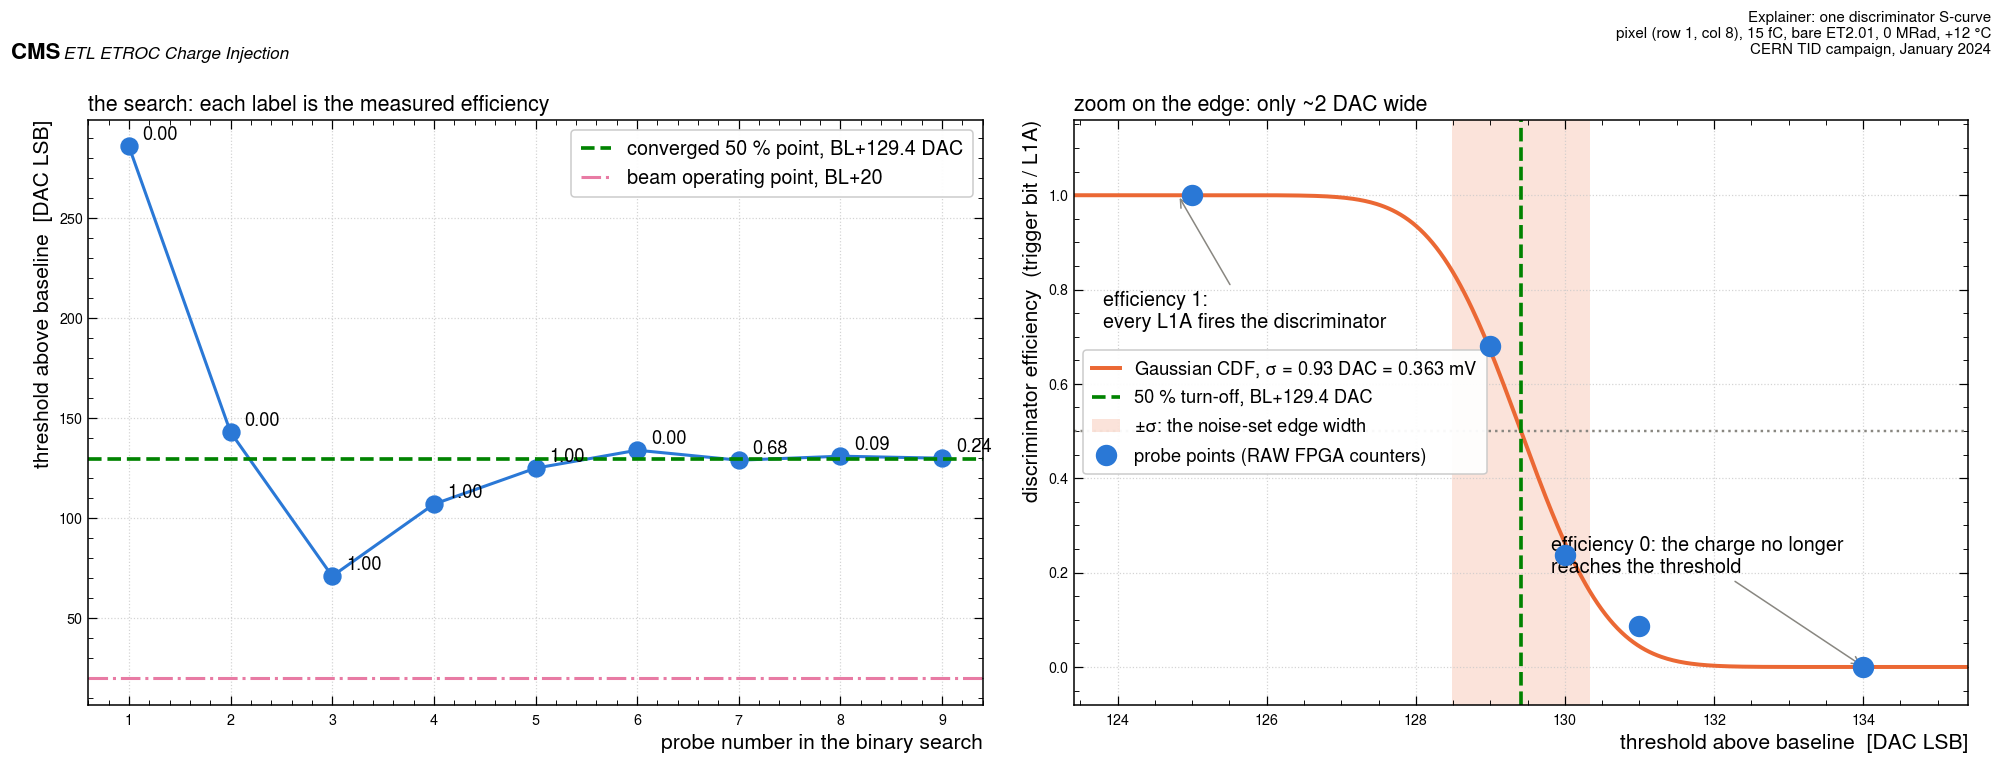

In [9]:
# --- Explainer 1: one discriminator S-curve, with its width and its 50 % point marked.
g = csv[(csv.day == "2024-01-11") & (csv.row == 1) & (csv.col == 8) & (csv.charge == 15)].sort_values("dac")
bl_ex = float(BL[(BL.dose == 0) & (BL.temp == 12) & (BL.row == 1) & (BL.col == 8)].BL.iloc[0])
cv_ex, _ = Q.curves_from(g, keys=("row", "col", "charge"))
sig_ex, _, mu_ex, _ = Q.scurve_sigma(cv_ex, boot=0)
mu_ex = mu_ex[0]
to_ex = Q.turnoff_50pct(g.dac, g.frac)

fig, axs = plt.subplots(1, 2, figsize=(18, 6.4))
ax = axs[0]
gs = g.sort_values("c0_elapsed") if "c0_elapsed" in g else g
ax.plot(np.arange(1, len(gs) + 1), gs.dac - bl_ex, "o-", ms=11, lw=2.0, color=Q.C_BLUE)
for i, (d_, f_) in enumerate(zip(gs.dac, gs.frac), start=1):
    ax.annotate(f"{f_:.2f}", (i, d_ - bl_ex), textcoords="offset points", xytext=(9, 4), fontsize=12)
ax.axhline(to_ex - bl_ex, color=Q.C_GREEN, ls="--", lw=2.4,
           label=f"converged 50 % point, BL+{to_ex - bl_ex:.1f} DAC")
ax.axhline(Q.OP_OFFSET, color=Q.C_MAG, ls="-.", lw=2.0, label="beam operating point, BL+20")
ax.set_xlabel("probe number in the binary search")
ax.set_ylabel("threshold above baseline  [DAC LSB]")
ax.set_title("the search: each label is the measured efficiency", loc="left", fontsize=14)
ax.legend(fontsize=13, loc="upper right")

ax = axs[1]
ax.errorbar(g.dac - bl_ex, g.frac, yerr=np.sqrt(np.clip(g.frac, 0, 1) * (1 - np.clip(g.frac, 0, 1)) / g.header_max),
            fmt="o", ms=13, color=Q.C_BLUE, zorder=5, label="probe points (RAW FPGA counters)")
xx = np.linspace(mu_ex - 8, mu_ex + 8, 600)
ax.plot(xx - bl_ex, Q.gauss_cdf(xx, mu_ex, sig_ex), "-", color=Q.C_ORANGE, lw=2.6,
        label=f"Gaussian CDF, $\\sigma$ = {sig_ex:.2f} DAC = {sig_ex * Q.LSB_MV:.3f} mV")
ax.axhline(0.5, color=Q.GREY, ls=":", lw=1.6)
ax.axvline(to_ex - bl_ex, color=Q.C_GREEN, ls="--", lw=2.4,
           label=f"50 % turn-off, BL+{to_ex - bl_ex:.1f} DAC")
ax.axvspan(mu_ex - sig_ex - bl_ex, mu_ex + sig_ex - bl_ex, color=Q.C_ORANGE, alpha=0.18, lw=0,
           label="$\\pm\\sigma$: the noise-set edge width")
ax.set_xlim(mu_ex - 6 - bl_ex, mu_ex + 6 - bl_ex)
ax.annotate("efficiency 1:\nevery L1A fires the discriminator",
            xy=(mu_ex - 4.6 - bl_ex, 1.0), xytext=(mu_ex - 5.6 - bl_ex, 0.72), fontsize=13,
            arrowprops=dict(arrowstyle="->", color=Q.GREY))
ax.annotate("efficiency 0: the charge no longer\nreaches the threshold",
            xy=(mu_ex + 4.6 - bl_ex, 0.0), xytext=(mu_ex + 0.4 - bl_ex, 0.20), fontsize=13,
            arrowprops=dict(arrowstyle="->", color=Q.GREY))
ax.set_xlabel("threshold above baseline  [DAC LSB]")
ax.set_ylabel("discriminator efficiency  (trigger bit / L1A)")
ax.set_ylim(-0.08, 1.16)
ax.legend(loc="center left", fontsize=12)
ax.set_title("zoom on the edge: only ~2 DAC wide", loc="left", fontsize=14)
fig.tight_layout()
Q.fig_header(fig, "Explainer: one discriminator S-curve",
       tag="pixel (row 1, col 8), 15 fC, bare ET2.01, 0 MRad, +12 °C", scale=0.62, campaign=Q.BARE_CAMPAIGN)
Q.save_fig(fig, "bare_expl1_scurve")
plt.show()

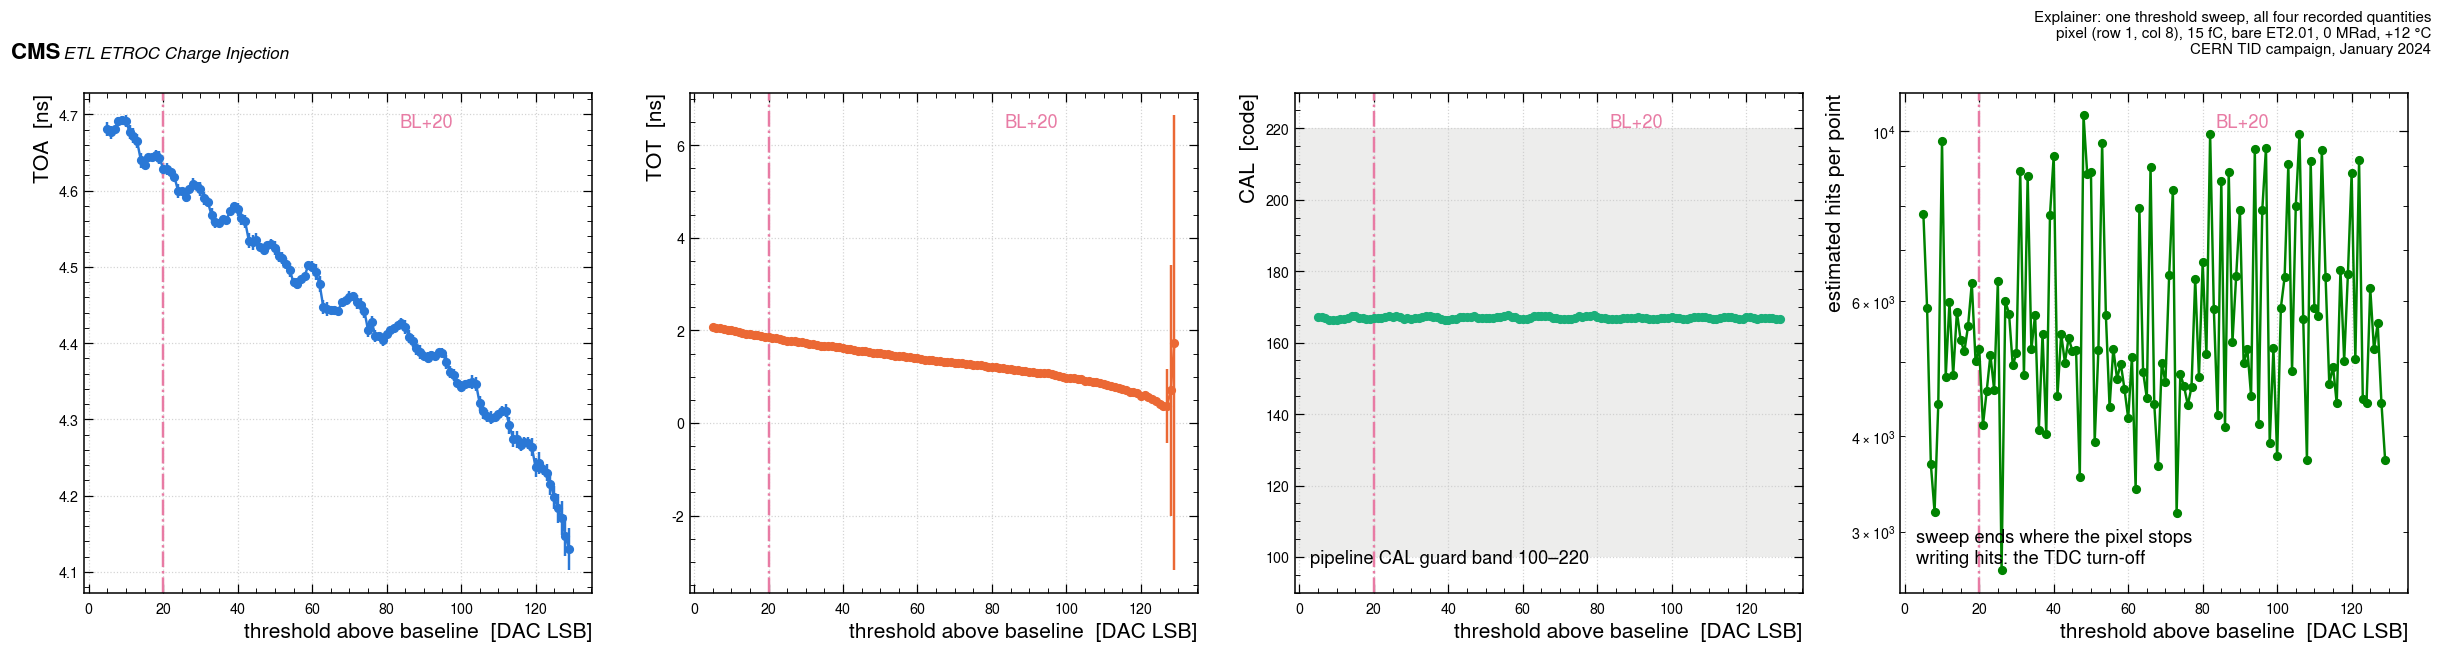

In [10]:
# --- Explainer 2: what one threshold sweep records — TOA, TOT and CAL against threshold.
pix, qq = (1, 8), 15
d = D0[(D0.row == pix[0]) & (D0.col == pix[1]) & (D0.charge == qq)].sort_values("offset")
fig, axs = plt.subplots(1, 4, figsize=(22, 5.4))
for ax, (col, lab, col_c) in zip(axs, [("toa_ns", "TOA  [ns]", Q.C_BLUE),
                                       ("tot_ns", "TOT  [ns]", Q.C_ORANGE),
                                       ("cal_mean", "CAL  [code]", Q.C_AQUA),
                                       ("nhit_est", "estimated hits per point", Q.C_GREEN)]):
    yerr = None
    if col == "toa_ns":
        yerr = d.jitter_ps / 1e3
    if col == "tot_ns":
        yerr = d.tot_std_ns
    ax.errorbar(d.offset, d[col], yerr=yerr, fmt="o-", ms=5, lw=1.6, color=col_c)
    ax.set_xlabel("threshold above baseline  [DAC LSB]")
    ax.set_ylabel(lab)
    ax.axvline(Q.OP_OFFSET, color=Q.C_MAG, ls="-.", lw=1.6)
axs[2].axhspan(*Q.CAL_GUARD, color=Q.GREY, alpha=0.15, lw=0)
axs[2].set_ylim(min(Q.CAL_GUARD) - 10, max(Q.CAL_GUARD) + 10)
axs[2].text(0.03, 0.06, "pipeline CAL guard band 100–220", transform=axs[2].transAxes, fontsize=12)
axs[3].set_yscale("log")
axs[3].text(0.03, 0.06, "sweep ends where the pixel stops\nwriting hits: the TDC turn-off",
            transform=axs[3].transAxes, fontsize=12)
for ax in axs:
    ax.text(0.62, 0.93, "BL+20", transform=ax.transAxes, color=Q.C_MAG, fontsize=12)
fig.tight_layout()
Q.fig_header(fig, "Explainer: one threshold sweep, all four recorded quantities",
       tag=f"pixel (row {pix[0]}, col {pix[1]}), {qq} fC, bare ET2.01, 0 MRad, +12 °C", scale=0.62, campaign=Q.BARE_CAMPAIGN)
Q.save_fig(fig, "bare_expl2_sweep_quantities")
plt.show()

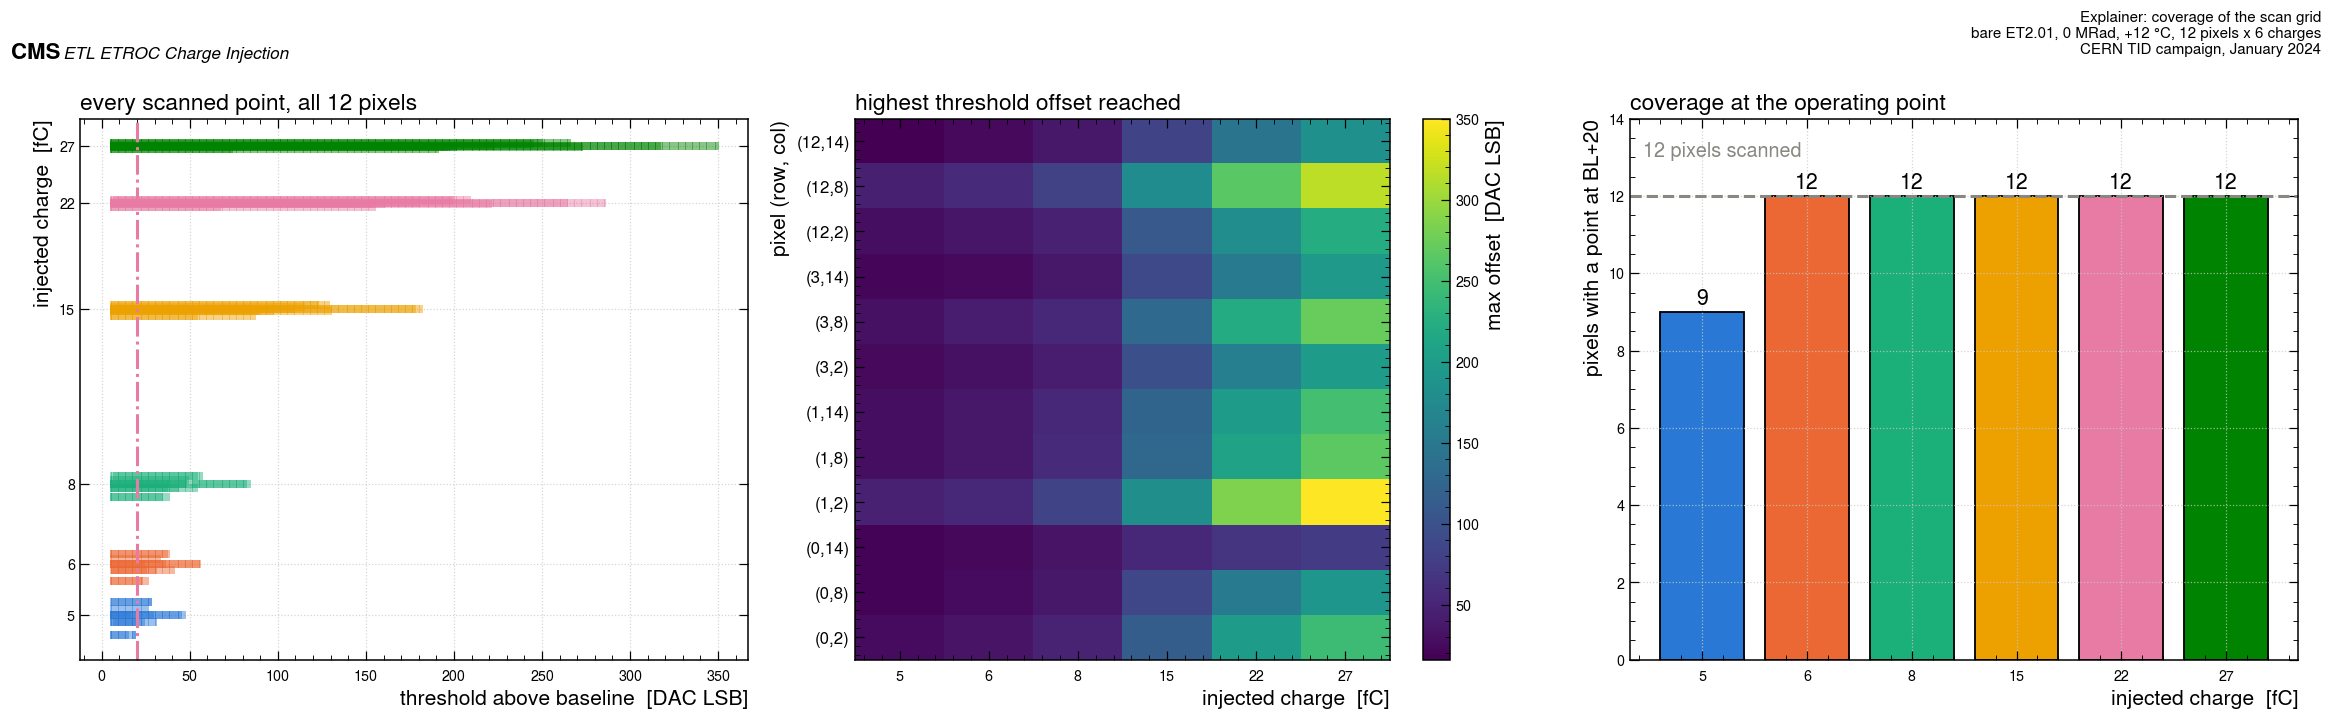

pixels with a point exactly at BL+20, by charge: {5: 9, 6: 12, 8: 12, 15: 12, 22: 12, 27: 12}


In [11]:
# --- Explainer 3: the coverage of the scan grid — threshold x charge x pixel.
fig, axs = plt.subplots(1, 3, figsize=(21, 6.0))
ax = axs[0]
for ch in Q.CHARGES:
    sub = D0[D0.charge == ch]
    for (r, c), gg in sub.groupby(["row", "col"]):
        ax.plot(gg.offset, np.full(len(gg), ch) + 0.35 * (hash((r, c)) % 7 - 3) / 3,
                "|", ms=5, color=Q.CCOL[ch], alpha=0.6)
Q.charge_axis(ax, axis="y")
ax.set_xlabel("threshold above baseline  [DAC LSB]")
ax.set_ylabel("injected charge  [fC]")
ax.set_title("every scanned point, all 12 pixels", loc="left", fontsize=15)
ax.axvline(Q.OP_OFFSET, color=Q.C_MAG, ls="-.", lw=2)

ax = axs[1]
cover = (D0.groupby(["row", "col", "charge"]).offset.max().reset_index()
           .pivot_table(index=["row", "col"], columns="charge", values="offset"))
im = ax.imshow(cover.values, aspect="auto", cmap="viridis", origin="lower")
ax.set_xticks(range(len(cover.columns)))
ax.set_xticklabels([str(c) for c in cover.columns])
ax.set_yticks(range(len(cover.index)))
ax.set_yticklabels([f"({r},{c})" for r, c in cover.index], fontsize=11)
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("pixel (row, col)")
ax.set_title("highest threshold offset reached", loc="left", fontsize=15)
ax.grid(False)
plt.colorbar(im, ax=ax, label="max offset  [DAC LSB]")

ax = axs[2]
n20 = (D0[D0.offset == Q.OP_OFFSET].groupby("charge").size()
       .reindex(Q.CHARGES).fillna(0).astype(int))
ax.bar([str(c) for c in Q.CHARGES], n20.values,
       color=[Q.CCOL[c] for c in Q.CHARGES], edgecolor="black", lw=1.2)
ax.axhline(12, color=Q.GREY, ls="--", lw=2)
ax.text(0.02, 0.93, "12 pixels scanned", transform=ax.transAxes, fontsize=13, color=Q.GREY)
for i, v in enumerate(n20.values):
    ax.text(i, v + 0.2, str(v), ha="center", fontsize=14)
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("pixels with a point at BL+20")
ax.set_ylim(0, 14)
ax.set_title("coverage at the operating point", loc="left", fontsize=15)
fig.tight_layout()
Q.fig_header(fig, "Explainer: coverage of the scan grid",
       tag="bare ET2.01, 0 MRad, +12 °C, 12 pixels x 6 charges", scale=0.62, campaign=Q.BARE_CAMPAIGN)
Q.save_fig(fig, "bare_expl3_scan_grid")
plt.show()
print("pixels with a point exactly at BL+20, by charge:", n20.to_dict())

The right-hand panel is the first real caveat of the analysis: **5 fC reaches the beam
operating point on only 9 of the 12 pixels.** No cut is applied anywhere in this notebook, so
nothing is thrown away — but a pooled number at 5 fC is an average over fewer pixels than a
pooled number at 15 fC, and every pooled table below carries its own `n` for that reason.

## 5. Two turn-offs, and why they disagree

"Turn-off" can mean two different things here and they are **not** interchangeable.

* The **discriminator turn-off** is the 50 % point of the binary search, from the trigger-bit
  counter, which has a real denominator (`header_max` ≈ 11 223 L1A). It is a genuine
  efficiency. **Below 8 fC it saturates** at a charge-independent floor, i.e. the trigger bit
  is responding to something that does not scale with the injected charge, so its slope there
  is not a gain.
* The **TDC-readout turn-off** is the highest threshold at which the sweep still wrote hits.
  It *is* linear in charge down to 5 fC. **But above 8 fC it is censored**, because the
  sweep's own upper bound was set to the binary search's answer: the scan stops while hits are
  still being recorded. Its apparent agreement with the discriminator turn-off above 8 fC is
  therefore partly by construction and is not an independent check.

So the gain fit below uses the **discriminator turn-off over 8–27 fC only**, and the TDC
turn-off over 5–8 fC is carried separately as a low-charge cross-check. The censoring flag is
computed, not assumed: the sweep's last scanned threshold comes from the directory census.

In [12]:
TO = Q.turnoff_table(PR, ["dose", "temp", "row", "col", "charge"])
TO = TO.merge(BL, on=["dose", "temp", "row", "col"], how="left")
tdc = (SW[SW.dir_bytes > 0].groupby(["dose", "temp", "row", "col", "charge"]).dac.max()
       .rename("tdc_turnoff_dac").reset_index())
smax = (SW.groupby(["dose", "temp", "row", "col", "charge"]).dac.max()
        .rename("sweep_dac_max").reset_index())
TO = (TO.merge(tdc, on=["dose", "temp", "row", "col", "charge"], how="left")
        .merge(smax, on=["dose", "temp", "row", "col", "charge"], how="left"))
TO["trig_turnoff_offset"] = TO.trig_turnoff_dac - TO.BL
TO["tdc_turnoff_offset"] = TO.tdc_turnoff_dac - TO.BL
TO["sweep_offset_max"] = TO.sweep_dac_max - TO.BL
TO["tdc_turnoff_censored"] = TO.tdc_turnoff_dac >= TO.sweep_dac_max
TO.to_csv(Q.OUTDIR / "bare_turnoff_all_conditions.csv", index=False)

t0 = TO[(TO.dose == 0) & (TO.temp == 12)]
tab = pd.DataFrame({
    "trig_turnoff_offset_mean": t0.groupby("charge").trig_turnoff_offset.mean(),
    "trig_pixel_rms": t0.groupby("charge").trig_turnoff_offset.std(),
    "tdc_turnoff_offset_mean": t0.groupby("charge").tdc_turnoff_offset.mean(),
    "tdc_pixel_rms": t0.groupby("charge").tdc_turnoff_offset.std(),
    "n_censored_of_12": t0.groupby("charge").tdc_turnoff_censored.sum(),
}).round(2)
print("0 MRad, +12 °C — both turn-off estimators, pooled over 12 pixels\n")
print(tab.to_string())
print("\nThe discriminator turn-off is flat from 5 to 8 fC (%.1f -> %.1f -> %.1f DAC): that is the"
      % tuple(tab.trig_turnoff_offset_mean[[5, 6, 8]]))
print("saturation described above. The TDC turn-off over the same charges rises %.1f -> %.1f -> %.1f."
      % tuple(tab.tdc_turnoff_offset_mean[[5, 6, 8]]))

for ch, want in zip([5, 6, 8, 15, 22, 27], [45.9, 47.3, 55.2, 116.0, 187.8, 232.1]):
    Q.check(f"discriminator turn-off above BL at {ch} fC", tab.trig_turnoff_offset_mean[ch],
            want, 0.15, "DAC", LEDGER)

0 MRad, +12 °C — both turn-off estimators, pooled over 12 pixels

        trig_turnoff_offset_mean  trig_pixel_rms  tdc_turnoff_offset_mean  tdc_pixel_rms  n_censored_of_12
charge                                                                                                    
5                          45.94            6.24                    27.75           9.69                 1
6                          47.34            7.41                    35.67          11.08                 2
8                          55.21           14.98                    51.58          16.40                 8
15                        116.03           37.23                   115.17          37.21                12
22                        187.77           58.03                   187.00          58.02                12
27                        232.09           71.31                   231.25          71.39                12

The discriminator turn-off is flat from 5 to 8 fC (45.9 -> 47.3 -> 55.2 DAC):

### A note on the turn-off estimator itself

The 50 % point is read off the search's own probe points by linear interpolation of the
efficiency between the highest probe still at or above 50 % and the lowest one above it that
is below 50 %. That is sub-LSB. A coarser alternative — simply "the highest probe at or above
50 %" — lands about half a probe step low. Both are implemented in `qinj_common.turnoff_50pct`
and the companion hybrid notebook uses the same function, so the two campaigns cannot differ
through this choice. The size of the difference is shown below.

In [13]:
alt = Q.turnoff_table(PR[(PR.dose == 0) & (PR.temp == 12)], ["row", "col", "charge"], method="maxdac")
cmp_ = (t0[["row", "col", "charge", "trig_turnoff_dac"]]
        .merge(alt[["row", "col", "charge", "trig_turnoff_dac"]], on=["row", "col", "charge"],
               suffixes=("_interp", "_maxdac")))
cmp_["delta"] = cmp_.trig_turnoff_dac_interp - cmp_.trig_turnoff_dac_maxdac
print("interpolated 50 %% point minus highest-probe-above-50 %%, over %d (pixel, charge) pairs:" % len(cmp_))
print("  mean %+.3f DAC, median %+.3f DAC, range %+.3f to %+.3f DAC"
      % (cmp_.delta.mean(), cmp_.delta.median(), cmp_.delta.min(), cmp_.delta.max()))

interpolated 50 % point minus highest-probe-above-50 %, over 72 (pixel, charge) pairs:
  mean +0.481 DAC, median +0.497 DAC, range +0.002 to +0.998 DAC


## 6. Preamp gain

The gain is the slope of discriminator turn-off against injected charge, fitted per pixel by
weighted least squares over **8–27 fC** with a y-error of 0.5 DAC (the binary search brackets
the crossing to 1 DAC). The result is quoted both in DAC per fC and, through the 0.390625 mV
LSB, in millivolts per fC.

In [14]:
rows = []
for (dose, temp, r, c), g in TO.groupby(["dose", "temp", "row", "col"]):
    rec = dict(dose=dose, temp=temp, row=r, col=c, BL=g.BL.iloc[0])
    rec.update(Q.gain_fit(g, g.BL.iloc[0]))
    lo = g[(g.charge <= 8) & g.tdc_turnoff_dac.notna() & (~g.tdc_turnoff_censored.fillna(False))]
    lo = lo.sort_values("charge")
    if len(lo) >= 2:
        s2, *_ = Q.wls(lo.charge, lo.tdc_turnoff_dac, np.full(len(lo), 0.5))
        rec["gain_lowQ_tdc_dac_per_fc"] = s2
        rec["npts_lowQ"] = len(lo)
    rows.append(rec)
GF = pd.DataFrame(rows)
GF.to_csv(Q.OUTDIR / "bare_gain_fits.csv", index=False)

gb = []
for (dose, temp), g in GF.groupby(["dose", "temp"]):
    p, pl = Q.pooled(g.gain_dac_per_fc), Q.pooled(g.gain_lowQ_tdc_dac_per_fc)
    pi, pq = Q.pooled(g.intercept_offset_dac), Q.pooled(g.Qmin_at_off_fC)
    gb.append(dict(dose=dose, temp=temp, n_pixels=p["n"],
                   gain_dac_per_fc=p["mean"], gain_sem=p["sem"], gain_pixel_rms=p["rms"],
                   gain_mv_per_fc=p["mean"] * Q.LSB_MV, gain_mv_sem=p["sem"] * Q.LSB_MV,
                   gain_mv_pixel_rms=p["rms"] * Q.LSB_MV,
                   gain_min=g.gain_dac_per_fc.min(), gain_max=g.gain_dac_per_fc.max(),
                   gain_lowQ_tdc=pl["mean"], gain_lowQ_sem=pl["sem"], gain_lowQ_n=pl["n"],
                   intercept_offset_dac=pi["mean"], intercept_offset_sem=pi["sem"],
                   Qmin_at_off20_fC=pq["mean"], Qmin_sem=pq["sem"], Qmin_pixel_rms=pq["rms"],
                   BL_mean=g.BL.mean()))
GB = pd.DataFrame(gb)
GB.to_csv(Q.OUTDIR / "bare_gain_by_condition.csv", index=False)
print(GB.round(3).to_string(index=False))

ref = GB[(GB.dose == 0) & (GB.temp == 12)].iloc[0]
print()
Q.check("gain, 0 MRad +12 °C", ref.gain_dac_per_fc, 9.42, 0.02, "DAC/fC", LEDGER)
Q.check("gain uncertainty on the mean", ref.gain_sem, 0.89, 0.02, "DAC/fC", LEDGER)
Q.check("gain pixel RMS", ref.gain_pixel_rms, 3.09, 0.02, "DAC/fC", LEDGER)
Q.check("gain in volts", ref.gain_mv_per_fc, 3.68, 0.01, "mV/fC", LEDGER)
Q.check("low-charge cross-check (TDC turn-off, 5-8 fC)", ref.gain_lowQ_tdc, 7.42, 0.02, "DAC/fC", LEDGER)
Q.check("fit intercept referred to the baseline", ref.intercept_offset_dac, -21.7, 0.1, "DAC", LEDGER)
Q.check("minimum charge reaching BL+20", ref.Qmin_at_off20_fC, 4.3, 0.06, "fC", LEDGER)
print("\nper-pixel gain spread: %.2f to %.2f DAC/fC, i.e. %.0f %% pixel RMS on a 12-pixel sample"
      % (ref.gain_min, ref.gain_max, 100 * ref.gain_pixel_rms / ref.gain_dac_per_fc))

 dose  temp  n_pixels  gain_dac_per_fc  gain_sem  gain_pixel_rms  gain_mv_per_fc  gain_mv_sem  gain_mv_pixel_rms  gain_min  gain_max  gain_lowQ_tdc  gain_lowQ_sem  gain_lowQ_n  intercept_offset_dac  intercept_offset_sem  Qmin_at_off20_fC  Qmin_sem  Qmin_pixel_rms  BL_mean
    0   -25        12            8.691     0.861           2.984           3.395        0.336              1.165     1.949    13.410            NaN            NaN            0                -9.913                 3.696             3.417     0.385           1.332  523.417
    0    12        12            9.416     0.892           3.090           3.678        0.348              1.207     2.177    14.235          7.421          0.750           10               -21.710                 4.511             4.257     0.431           1.493  446.500
  200   -25        12            8.315     0.826           2.862           3.248        0.323              1.118     1.877    11.938          7.064          0.794           10      

**The intercept is not the baseline, and that matters operationally.** Extrapolated to zero
charge the fitted turn-off does not land on the baseline; it lands about 22 DAC *below* it.
A pure proportionality would put it at 0. So `turn-off = BL + gain × Q` is the wrong model,
and estimating a gain by drawing a line from the baseline through one measured
(charge, turn-off) pair gives the wrong slope — it will read low.

**The pixel-to-pixel spread is the dominant uncertainty.** A 33 % RMS across 12 pixels means
a single chip-level "gain" is close to meaningless; the per-pixel numbers are what should be
carried forward, and they are in `outputs/bare_gain_fits.csv`.

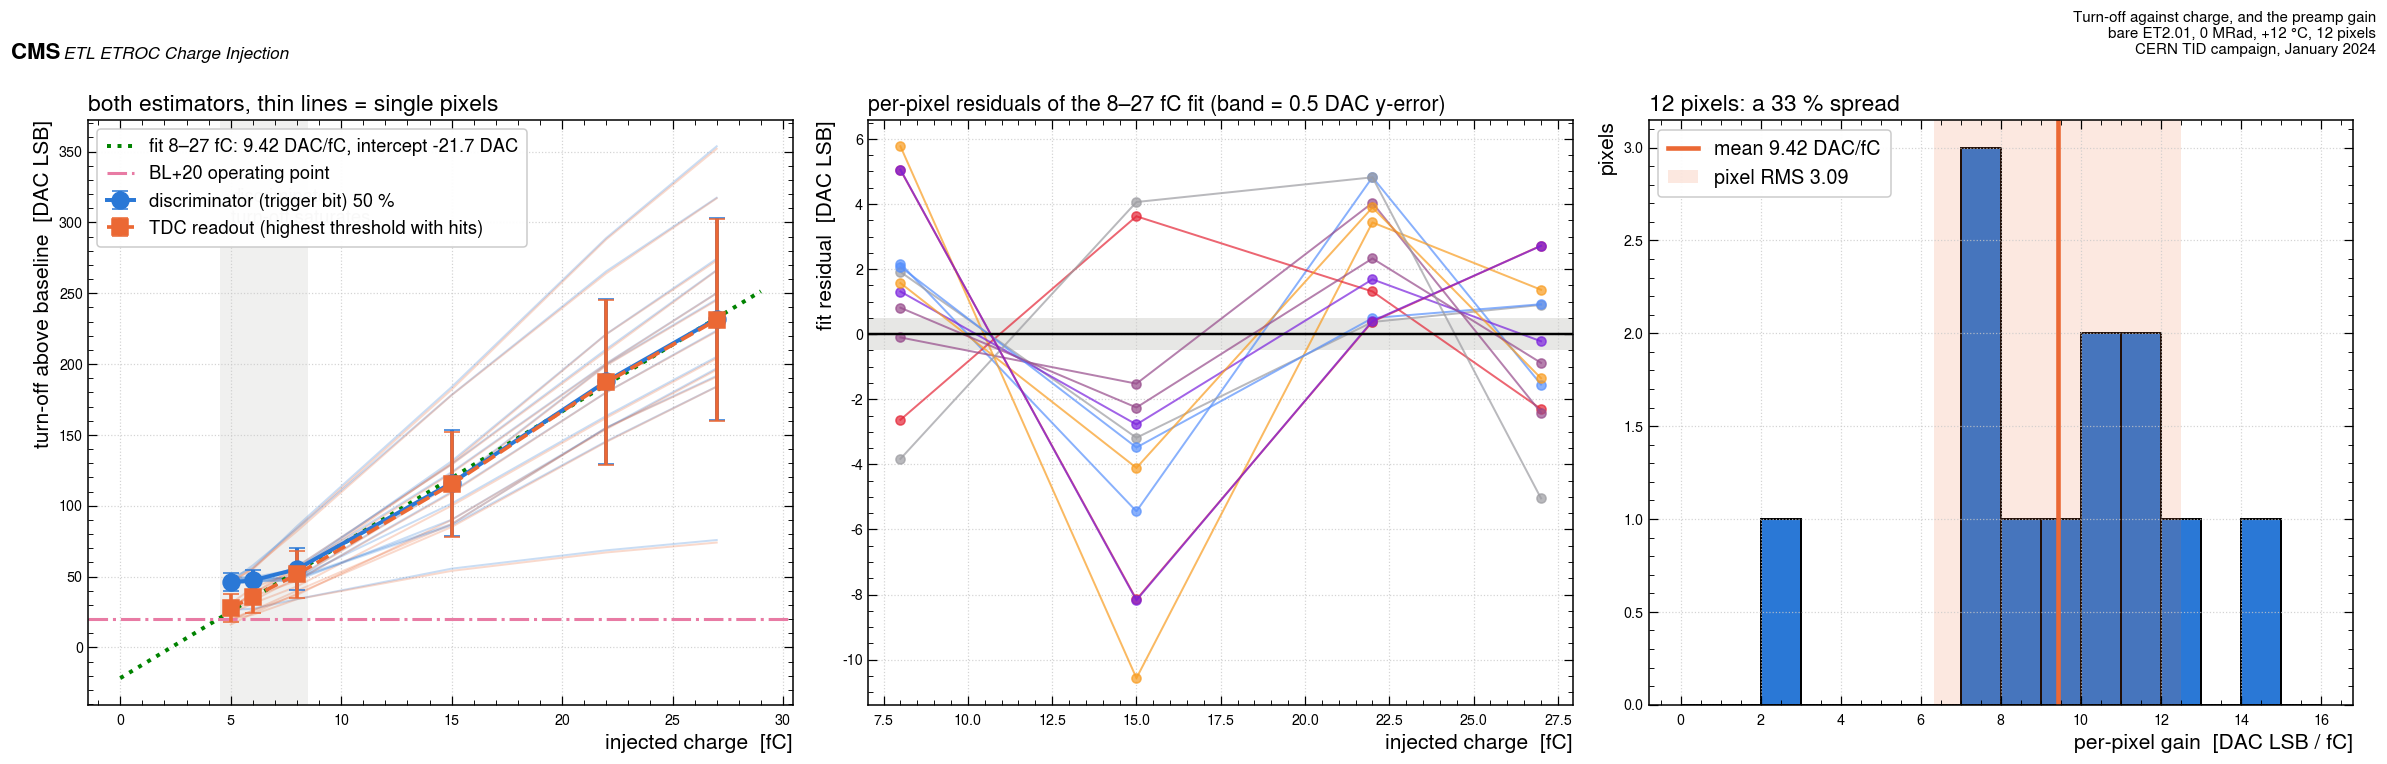

In [15]:
fig, axs = plt.subplots(1, 3, figsize=(21.5, 6.4))
ax = axs[0]
for (r, c), g in t0.groupby(["row", "col"]):
    g = g.sort_values("charge")
    ax.plot(g.charge, g.trig_turnoff_offset, "-", color=Q.C_BLUE, alpha=0.25, lw=1.3)
    ax.plot(g.charge, g.tdc_turnoff_offset, "-", color=Q.C_ORANGE, alpha=0.25, lw=1.3)
po = t0.groupby("charge").agg(trig=("trig_turnoff_offset", "mean"), trig_r=("trig_turnoff_offset", "std"),
                              tdc=("tdc_turnoff_offset", "mean"), tdc_r=("tdc_turnoff_offset", "std"))
ax.errorbar(po.index, po.trig, yerr=po.trig_r, fmt="o-", ms=11, lw=2.6, color=Q.C_BLUE,
            capsize=5, label="discriminator (trigger bit) 50 %", zorder=6)
ax.errorbar(po.index, po.tdc, yerr=po.tdc_r, fmt="s--", ms=10, lw=2.4, color=Q.C_ORANGE,
            capsize=5, label="TDC readout (highest threshold with hits)", zorder=6)
xf = np.linspace(0, 29, 50)
ax.plot(xf, ref.gain_dac_per_fc * xf + ref.intercept_offset_dac, ":", color=Q.C_GREEN, lw=2.6,
        label=f"fit 8–27 fC: {ref.gain_dac_per_fc:.2f} DAC/fC, intercept {ref.intercept_offset_dac:+.1f} DAC")
ax.axhline(Q.OP_OFFSET, color=Q.C_MAG, ls="-.", lw=2, label="BL+20 operating point")
ax.axvspan(4.5, 8.5, color=Q.GREY, alpha=0.12, lw=0)
ax.text(5.0, 300, "discriminator\nturn-off saturates", fontsize=12, color=Q.GREY)
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("turn-off above baseline  [DAC LSB]")
ax.legend(fontsize=12, loc="upper left")
ax.set_title("both estimators, thin lines = single pixels", loc="left", fontsize=15)

ax = axs[1]
for (r, c), g in t0.groupby(["row", "col"]):
    h = g[(g.charge >= 8)].sort_values("charge")
    f = GF[(GF.dose == 0) & (GF.temp == 12) & (GF.row == r) & (GF.col == c)]
    if not len(f) or pd.isna(f.gain_dac_per_fc.iloc[0]):
        continue
    resid = h.trig_turnoff_dac - (f.gain_dac_per_fc.iloc[0] * h.charge + f.intercept_dac.iloc[0])
    ax.plot(h.charge, resid, "o-", ms=6, alpha=0.7, lw=1.3)
ax.axhline(0, color="black", lw=1.6)
ax.axhspan(-0.5, 0.5, color=Q.GREY, alpha=0.2, lw=0)
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("fit residual  [DAC LSB]")
ax.set_title("per-pixel residuals of the 8–27 fC fit (band = 0.5 DAC y-error)", loc="left", fontsize=14)

ax = axs[2]
g12 = GF[(GF.dose == 0) & (GF.temp == 12)].gain_dac_per_fc.dropna()
ax.hist(g12, bins=np.arange(0, 16.1, 1.0), color=Q.C_BLUE, edgecolor="black", lw=1.3)
ax.axvline(g12.mean(), color=Q.C_ORANGE, lw=3, label=f"mean {g12.mean():.2f} DAC/fC")
ax.axvspan(g12.mean() - g12.std(), g12.mean() + g12.std(), color=Q.C_ORANGE, alpha=0.15, lw=0,
           label=f"pixel RMS {g12.std():.2f}")
ax.set_xlabel("per-pixel gain  [DAC LSB / fC]")
ax.set_ylabel("pixels")
ax.legend(fontsize=13)
ax.set_title("12 pixels: a 33 % spread", loc="left", fontsize=15)
fig.tight_layout()
Q.fig_header(fig, "Turn-off against charge, and the preamp gain",
       tag="bare ET2.01, 0 MRad, +12 °C, 12 pixels", scale=0.62, campaign=Q.BARE_CAMPAIGN)
Q.save_fig(fig, "bare_fig1_turnoff_and_gain")
plt.show()

## 7. The money plot

TOA jitter against threshold, one curve per injected charge. The jitter is the per-point TOA
standard deviation converted to picoseconds through that point's own CAL,
`jitter = TOA_std × 3.125 / CAL`.

The quantisation floor is drawn on the figure and it dominates the reading. At the median CAL
of this block one TOA code is `3.125 ns / CAL`; a uniformly filled bin has RMS `LSB/√12`.

median CAL over the block  167.9 codes
one TOA code               18.61 ps
quantisation floor LSB/sqrt(12)  5.37 ps
[OK  ] TDC quantisation floor                               recomputed     5.3717  published     5.4000  |d|   0.0283 (tol 0.05) ps


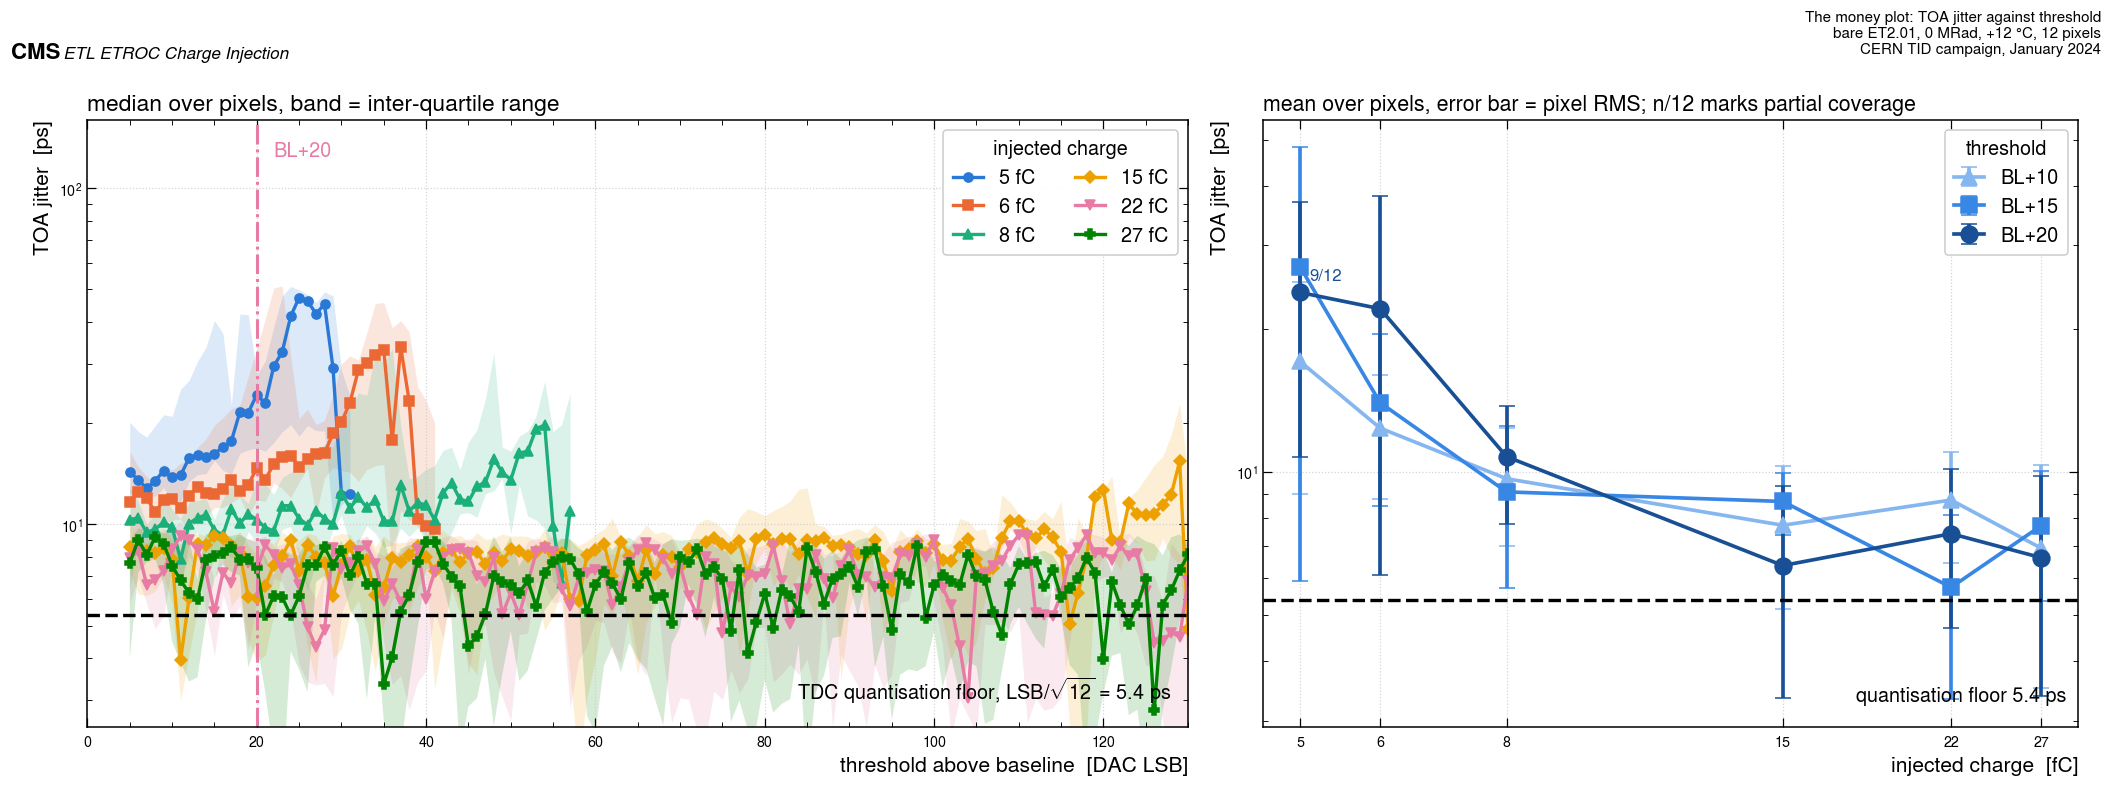


TOA jitter at BL+20 [ps], mean over pixels:
         mean    std  size
charge                    
5       23.88  13.12     9
6       22.07  16.00    12
8       10.78   3.02    12
15       6.36   3.01    12
22       7.42   2.72    12
27       6.61   3.23    12
[OK  ] TOA jitter at BL+20, 5 fC                            recomputed    23.8838  published    23.9000  |d|   0.0162 (tol 0.06) ps
[OK  ] TOA jitter at BL+20, 6 fC                            recomputed    22.0738  published    22.1000  |d|   0.0262 (tol 0.06) ps
[OK  ] TOA jitter at BL+20, 8 fC                            recomputed    10.7792  published    10.8000  |d|   0.0208 (tol 0.06) ps
[OK  ] TOA jitter at BL+20, 15 fC                           recomputed     6.3587  published     6.4000  |d|   0.0413 (tol 0.06) ps
[OK  ] TOA jitter at BL+20, 22 fC                           recomputed     7.4203  published     7.4000  |d|   0.0203 (tol 0.06) ps
[OK  ] TOA jitter at BL+20, 27 fC                           recomputed     6.60

In [16]:
lsb_ps, floor_ps = Q.quantisation_floor_ps(D0.cal_mean.median())
print("median CAL over the block  %.1f codes" % D0.cal_mean.median())
print("one TOA code               %.2f ps" % lsb_ps)
print("quantisation floor LSB/sqrt(12)  %.2f ps" % floor_ps)
Q.check("TDC quantisation floor", floor_ps, 5.4, 0.05, "ps", LEDGER)
RESULTS["quantisation_floor_ps"] = floor_ps
RESULTS["toa_lsb_ps"] = lsb_ps

fig, axs = plt.subplots(1, 2, figsize=(19, 6.6), gridspec_kw=dict(width_ratios=[1.35, 1]))
ax = axs[0]
for ch in Q.CHARGES:
    sub = D0[D0.charge == ch]
    if not len(sub):
        continue
    grp = sub.groupby("offset").jitter_ps
    med, q1, q3, n = grp.median(), grp.quantile(0.25), grp.quantile(0.75), grp.size()
    keep = n >= 3
    ax.plot(med.index[keep], med[keep], "-", marker=Q.CMK[ch], ms=6, lw=2.2, color=Q.CCOL[ch],
            label=f"{ch} fC")
    ax.fill_between(med.index[keep], q1[keep], q3[keep], color=Q.CCOL[ch], alpha=0.16, lw=0)
ax.axhline(floor_ps, color="black", ls="--", lw=2.2)
ax.axvline(Q.OP_OFFSET, color=Q.C_MAG, ls="-.", lw=2)
ax.set_yscale("log")
ax.set_xlim(0, 130)
ax.set_ylim(2.5, 160)
ax.text(0.985, 0.035, f"TDC quantisation floor, LSB/$\\sqrt{{12}}$ = {floor_ps:.1f} ps",
        transform=ax.transAxes, fontsize=13, ha="right", va="bottom")
ax.text(Q.OP_OFFSET + 2, 0.94, "BL+20", color=Q.C_MAG, fontsize=13,
        transform=ax.get_xaxis_transform())
ax.set_xlabel("threshold above baseline  [DAC LSB]")
ax.set_ylabel("TOA jitter  [ps]")
ax.legend(title="injected charge", ncol=2, fontsize=13, title_fontsize=13)
ax.set_title("median over pixels, band = inter-quartile range", loc="left", fontsize=15)

ax = axs[1]
jit_off = {}
for off in Q.OFFS:
    sel = D0[D0.offset == off]
    p = sel.groupby("charge").jitter_ps.agg(["mean", "std", "size"])
    jit_off[off] = p
    ax.errorbar(p.index, p["mean"], yerr=p["std"], fmt="-", marker=Q.OMK[off], ms=11, lw=2.4,
                color=Q.OCOL[off], capsize=5, label=f"BL+{off}")
    for ch in p.index:
        if p.loc[ch, "size"] < 12:
            ax.annotate(f"{int(p.loc[ch, 'size'])}/12", (ch, p.loc[ch, "mean"]),
                        textcoords="offset points", xytext=(6, 8), fontsize=11, color=Q.OCOL[off])
ax.axhline(floor_ps, color="black", ls="--", lw=2.2)
ax.text(0.985, 0.035, f"quantisation floor {floor_ps:.1f} ps", transform=ax.transAxes,
        fontsize=13, ha="right", va="bottom")
Q.charge_axis(ax)
ax.set_yscale("log")
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("TOA jitter  [ps]")
ax.legend(title="threshold", fontsize=13, title_fontsize=13)
ax.set_title("mean over pixels, error bar = pixel RMS; n/12 marks partial coverage",
             loc="left", fontsize=14)
fig.tight_layout()
Q.fig_header(fig, "The money plot: TOA jitter against threshold",
       tag="bare ET2.01, 0 MRad, +12 °C, 12 pixels", scale=0.62, campaign=Q.BARE_CAMPAIGN)
Q.save_fig(fig, "bare_fig2_money_plot")
plt.show()

j20 = jit_off[20]
print("\nTOA jitter at BL+20 [ps], mean over pixels:")
print(j20.round(2).to_string())
for ch, want in zip(Q.CHARGES, [23.9, 22.1, 10.8, 6.4, 7.4, 6.6]):
    Q.check(f"TOA jitter at BL+20, {ch} fC", j20.loc[ch, "mean"], want, 0.06, "ps", LEDGER)

**Read this before quoting anything off that figure.** For 8 fC and above the measured jitter
is within a factor of about 1.3 of the quantisation floor, and `TOA_std` is roughly a third of
one TOA code: nearly every hit lands in one or two TDC bins. Those points are **limits, not
resolutions**. Only the 5 and 6 fC points rise clearly above the floor and carry information
about the front end.

There are two reasons this is expected rather than a mistake. The injection is synchronous
with the clock, so there is no genuine time-of-arrival spread to resolve; and there is no
sensor, so there is neither a Landau fluctuation nor sensor noise contributing. The practical
consequence is that **the high-charge branch of this plot must not be compared with a beam
per-board time resolution**. The part that is physically meaningful is the low-charge rise,
and the threshold-edge width in the next section.

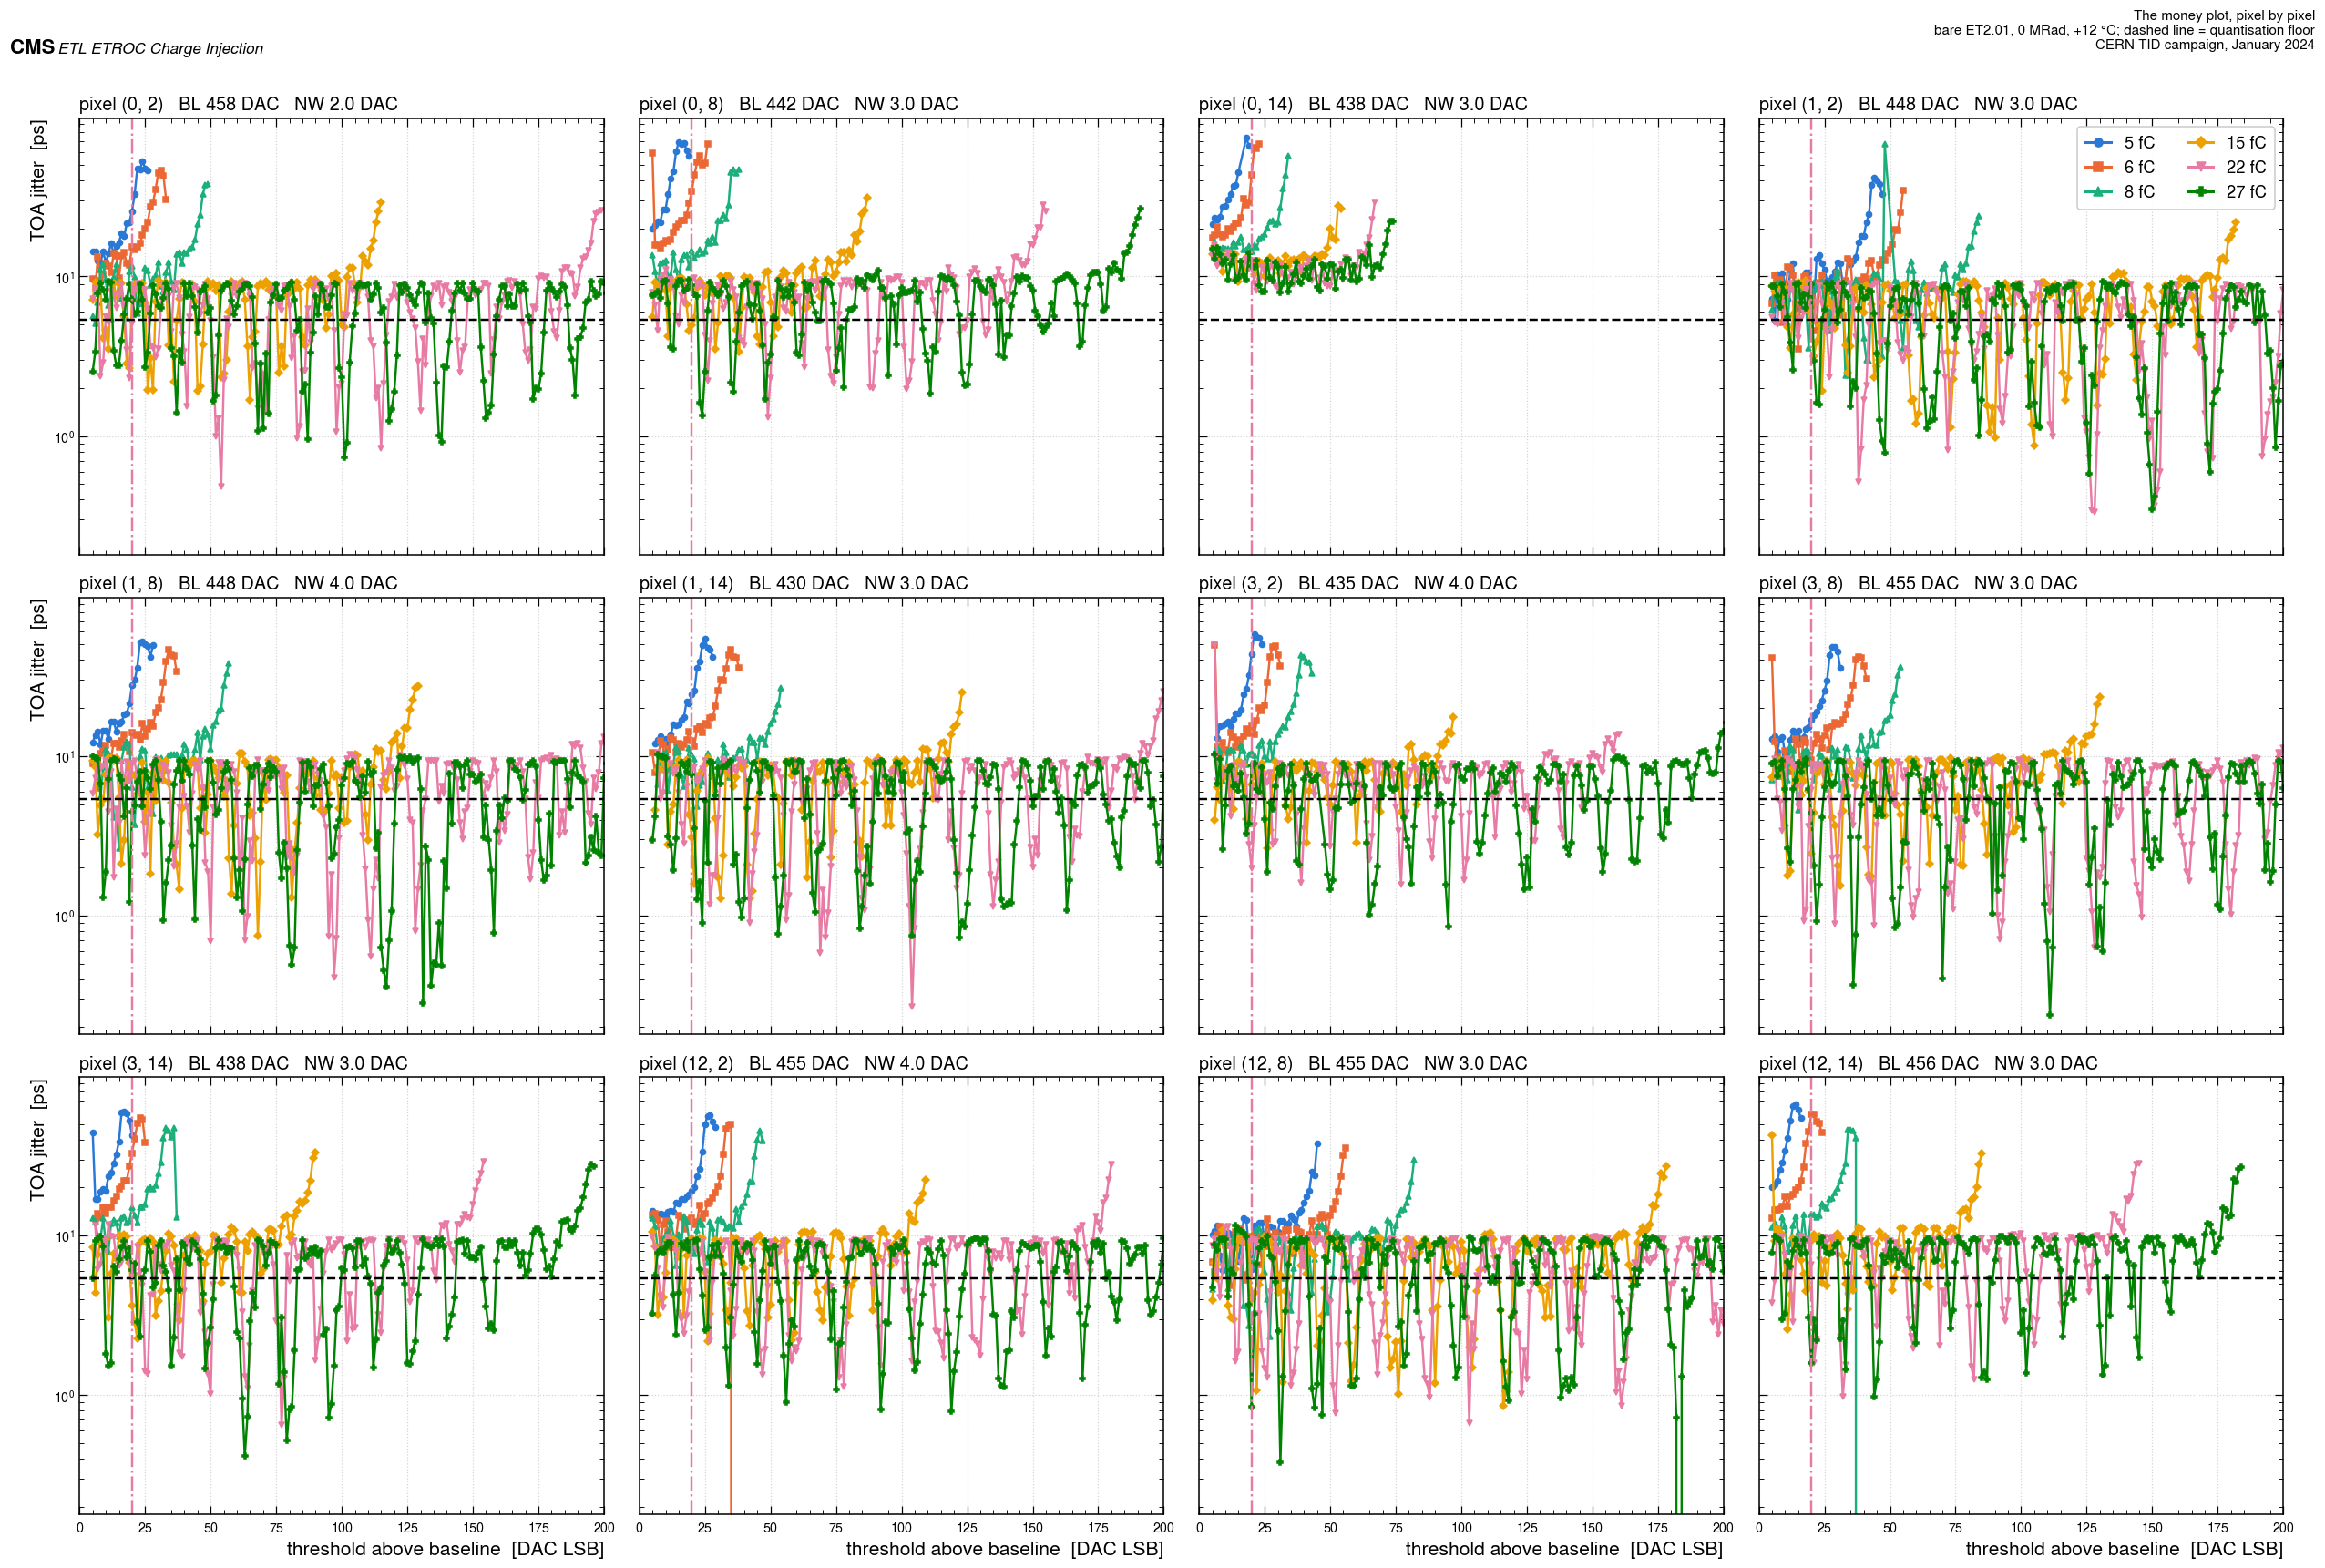

In [17]:
fig, axs = plt.subplots(3, 4, figsize=(23, 15), sharex=True, sharey=True)
for ax, ((r, c), g) in zip(axs.ravel(), D0.groupby(["row", "col"])):
    for ch in Q.CHARGES:
        s = g[g.charge == ch].sort_values("offset")
        if len(s) < 2:
            continue
        ax.plot(s.offset, s.jitter_ps, "-", marker=Q.CMK[ch], ms=4, lw=1.6, color=Q.CCOL[ch])
    ax.axhline(floor_ps, color="black", ls="--", lw=1.6)
    ax.axvline(Q.OP_OFFSET, color=Q.C_MAG, ls="-.", lw=1.6)
    bl_i = float(g.BL.iloc[0])
    nw_i = g.NW.iloc[0]
    ax.set_yscale("log")
    ax.set_title(f"pixel ({r}, {c})   BL {bl_i:.0f} DAC   NW {nw_i:.1f} DAC",
                 loc="left", fontsize=13)
for ax in axs[-1]:
    ax.set_xlabel("threshold above baseline  [DAC LSB]")
for ax in axs[:, 0]:
    ax.set_ylabel("TOA jitter  [ps]")
axs[0, 0].set_xlim(0, 200)
handles = [plt.Line2D([], [], color=Q.CCOL[c], marker=Q.CMK[c], lw=2, label=f"{c} fC") for c in Q.CHARGES]
axs[0, -1].legend(handles=handles, fontsize=12, ncol=2, loc="upper right")
fig.tight_layout()
Q.fig_header(fig, "The money plot, pixel by pixel",
       tag="bare ET2.01, 0 MRad, +12 °C; dashed line = quantisation floor", scale=0.62, campaign=Q.BARE_CAMPAIGN)
Q.save_fig(fig, "bare_fig3_money_plot_per_pixel")
plt.show()

## 8. The threshold edge: S-curve width, noise width and ENC

Every binary search leaves behind its probe points, and those probe points *are* an S-curve
with a real denominator. All 72 of them (12 pixels × 6 charges) are fitted here with **one
shared Gaussian width σ and a free 50 % point per curve, profiled out**, with the uncertainty
from a bootstrap over curves.

The shared-σ recipe is used rather than the simpler "align each curve on its own 50 % point,
then fit the stack", because the alignment absorbs part of the spread and biases σ low. The
same function fits the hybrid campaign in the companion notebook, so the two cannot differ
through this choice.

From σ and the gain follows the **equivalent noise charge**, `ENC = σ / gain`, expressed in
electrons. It is a ratio of two measured quantities, so whenever it moves it is worth saying
which of the two moved.

In [18]:
P0 = PR[(PR.dose == 0) & (PR.temp == 12)]
curves, meta = Q.curves_from(P0, keys=("row", "col", "charge"))
sigma, sigma_sd, mus, prof = Q.scurve_sigma(curves, boot=200)
gain0 = ref.gain_dac_per_fc
enc = Q.enc_electrons(sigma, gain0)
nw0 = Q.pooled(BL[(BL.dose == 0) & (BL.temp == 12)].NW)

print("S-curves fitted            %d  (12 pixels x 6 charges)" % len(curves))
print("shared-sigma fit           sigma = %.3f +- %.3f DAC = %.4f mV" % (sigma, sigma_sd, sigma * Q.LSB_MV))
print("gain                       %.3f DAC/fC" % gain0)
print("ENC = sigma / gain         %.0f electrons" % enc)
print("autocal noise width NW     %.3f +- %.3f DAC (pixel RMS %.3f)" % (nw0["mean"], nw0["sem"], nw0["rms"]))
print("NW / sigma                 %.2f" % (nw0["mean"] / sigma))
Q.check("autocal noise width NW", nw0["mean"], 3.17, 0.01, "DAC", LEDGER)
Q.check("NW pixel RMS", nw0["rms"], 0.58, 0.01, "DAC", LEDGER)
Q.check("S-curve width sigma", sigma, 0.88, 0.02, "DAC", LEDGER)
Q.check("ENC", enc, 584, 10, "electrons", LEDGER)

# The alternative estimator, for completeness: align each curve on its fitted 50 % point, stack,
# and fit one width to the stack.
from scipy.optimize import curve_fit as _cf
al_x = np.concatenate([d - m for (d, f), m in zip(curves, mus)])
al_y = np.concatenate([f for d, f in curves])
sig_aligned = float(_cf(lambda x, s: Q.gauss_cdf(x, 0.0, s), al_x, al_y, p0=[1.0])[0][0])
print("\naligned-and-stacked estimator on the same 72 curves: sigma = %.3f DAC -> ENC %.0f e-"
      % (sig_aligned, Q.enc_electrons(sig_aligned, gain0)))

RESULTS.update(sigma_dac=float(sigma), sigma_sd=float(sigma_sd),
               sigma_aligned_dac=sig_aligned, enc_e=float(enc), gain_dac_per_fc=float(gain0),
               nw_dac=float(nw0["mean"]), nw_rms=float(nw0["rms"]))

S-curves fitted            72  (12 pixels x 6 charges)
shared-sigma fit           sigma = 0.920 +- 0.052 DAC = 0.3594 mV
gain                       9.416 DAC/fC
ENC = sigma / gain         610 electrons
autocal noise width NW     3.167 +- 0.167 DAC (pixel RMS 0.577)
NW / sigma                 3.44
[OK  ] autocal noise width NW                               recomputed     3.1667  published     3.1700  |d|   0.0033 (tol 0.01) DAC
[OK  ] NW pixel RMS                                         recomputed     0.5774  published     0.5800  |d|   0.0026 (tol 0.01) DAC
[DIFF] S-curve width sigma                                  recomputed     0.9200  published     0.8800  |d|   0.0400 (tol 0.02) DAC
[DIFF] ENC                                                  recomputed   609.8375  published   584.0000  |d|  25.8375 (tol 10) electrons

aligned-and-stacked estimator on the same 72 curves: sigma = 0.921 DAC -> ENC 611 e-


In [19]:
sig_by_cond = {}
for (dose, temp), g in PR.groupby(["dose", "temp"]):
    cv, _ = Q.curves_from(g, keys=("row", "col", "charge"))
    s, sd, _, _ = Q.scurve_sigma(cv, boot=120)
    gv = GB[(GB.dose == dose) & (GB.temp == temp)].gain_dac_per_fc.iloc[0]
    sig_by_cond[(dose, temp)] = dict(sigma=s, sd=sd, n_curves=len(cv), gain=gv,
                                     enc=Q.enc_electrons(s, gv))
SIGT = pd.DataFrame(sig_by_cond).T.rename_axis(["dose", "temp"]).reset_index()
SIGT.to_csv(Q.OUTDIR / "bare_scurve_sigma_by_condition.csv", index=False)
print(SIGT.round(3).to_string(index=False))
print("\nThe edge width is flat across dose and temperature within its bootstrap error;")
print("what moves the ENC between conditions is the gain, not the edge.")

 dose  temp  sigma    sd  n_curves  gain     enc
    0   -25   0.94 0.048      72.0 8.691 675.073
    0    12   0.92 0.050      72.0 9.416 609.838
  200   -25   0.97 0.057      72.0 8.315 728.154
  400   -25   0.90 0.055      72.0 8.216 683.731

The edge width is flat across dose and temperature within its bootstrap error;
what moves the ENC between conditions is the gain, not the edge.


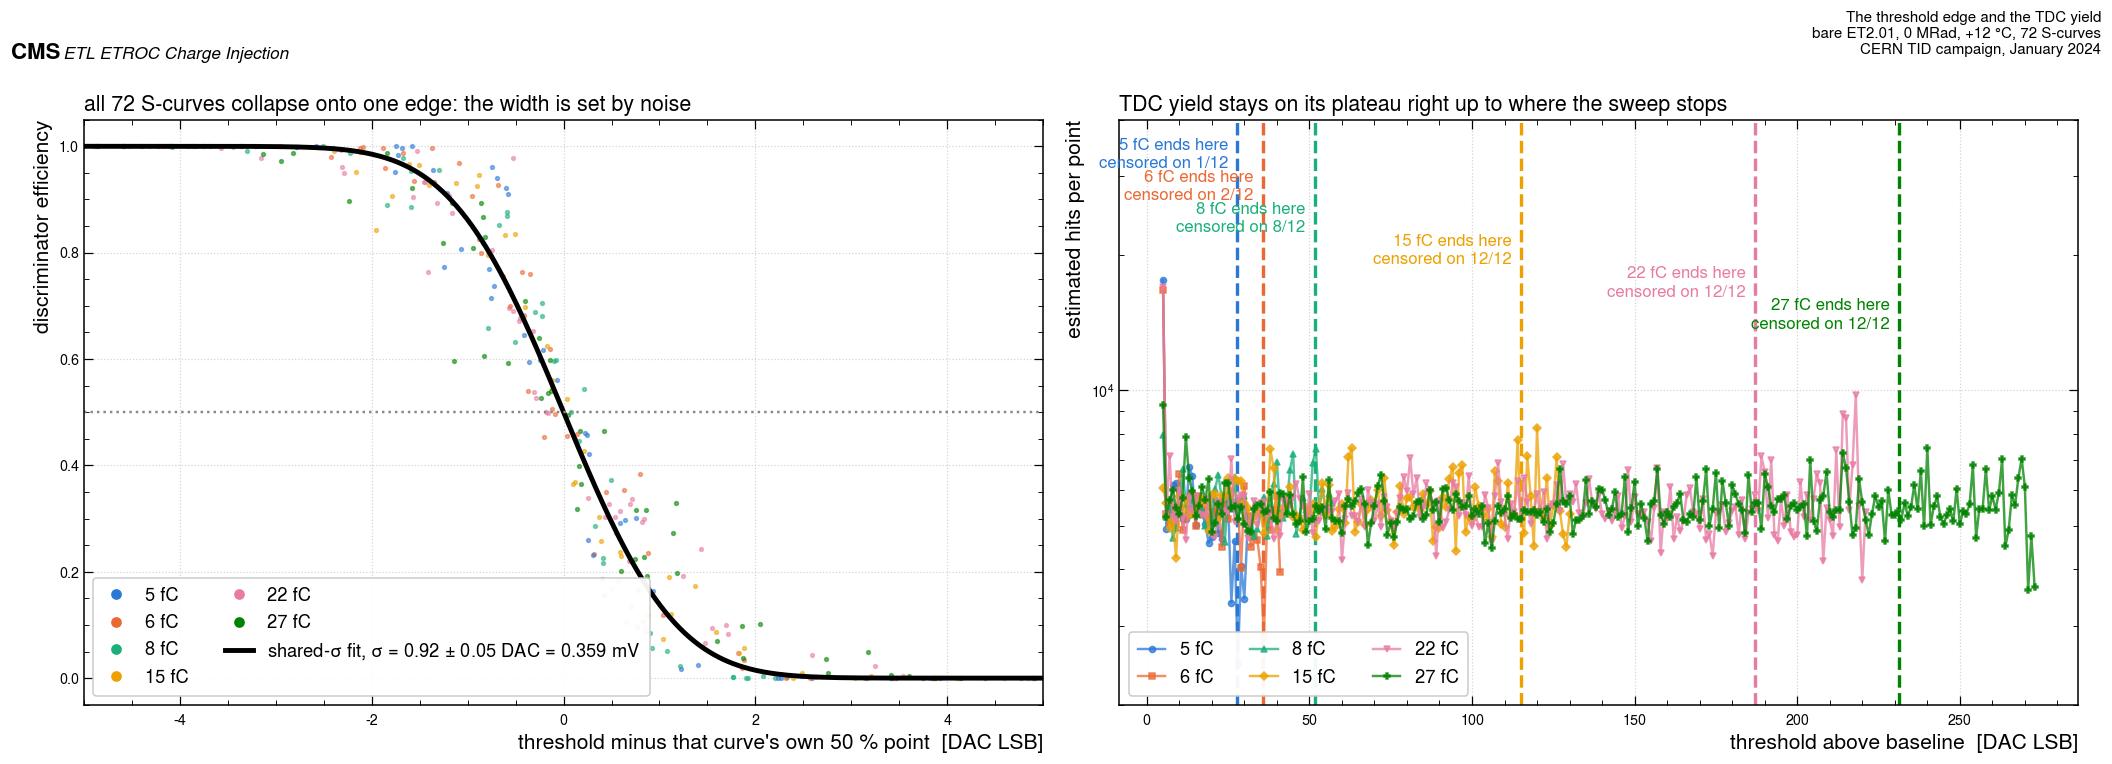

censored (pixel, charge) pairs by charge: {5: 1, 6: 2, 8: 8, 15: 12, 22: 12, 27: 12}


In [20]:
fig, axs = plt.subplots(1, 2, figsize=(19, 6.4))
ax = axs[0]
for (d, f), m, k in zip(curves, mus, meta):
    ax.plot(d - m, f, ".", ms=5, color=Q.CCOL[k[2]], alpha=0.55)
xx = np.linspace(-5, 5, 400)
ax.plot(xx, Q.gauss_cdf(xx, 0.0, sigma), "-", color="black", lw=3.2,
        label=f"shared-$\\sigma$ fit, $\\sigma$ = {sigma:.2f} $\\pm$ {sigma_sd:.2f} DAC = {sigma * Q.LSB_MV:.3f} mV")
ax.axhline(0.5, color=Q.GREY, ls=":", lw=1.6)
ax.set_xlim(-5, 5)
ax.set_xlabel("threshold minus that curve's own 50 % point  [DAC LSB]")
ax.set_ylabel("discriminator efficiency")
handles = [plt.Line2D([], [], color=Q.CCOL[c], marker="o", ls="", label=f"{c} fC") for c in Q.CHARGES]
ax.legend(handles=handles + ax.get_legend_handles_labels()[0], fontsize=12, ncol=2, loc="lower left")
ax.set_title(f"all {len(curves)} S-curves collapse onto one edge: the width is set by noise",
             loc="left", fontsize=14)

ax = axs[1]
for ch in Q.CHARGES:
    sub = D0[D0.charge == ch]
    grp = sub.groupby("offset").nhit_est
    med, n = grp.median(), grp.size()
    keep = n >= 3
    ax.plot(med.index[keep], med[keep], "-", marker=Q.CMK[ch], ms=4, lw=1.6, color=Q.CCOL[ch],
            alpha=0.75, label=f"{ch} fC")
    tt = t0[t0.charge == ch]
    end = float(tt.tdc_turnoff_offset.mean())
    ncen = int(tt.tdc_turnoff_censored.sum())
    ax.axvline(end, color=Q.CCOL[ch], ls="--", lw=2.2)
    ax.annotate(f"{ch} fC ends here\ncensored on {ncen}/12", (end, 0.97 - 0.055 * Q.CHARGES.index(ch)),
                xycoords=ax.get_xaxis_transform(), textcoords="offset points", xytext=(-6, 0),
                ha="right", va="top", fontsize=11, color=Q.CCOL[ch])
ax.set_yscale("log")
ax.set_ylim(2e3, 4e4)
ax.set_xlabel("threshold above baseline  [DAC LSB]")
ax.set_ylabel("estimated hits per point")
ax.legend(fontsize=12, ncol=3, loc="lower left")
ax.set_title("TDC yield stays on its plateau right up to where the sweep stops",
             loc="left", fontsize=14)
fig.tight_layout()
Q.fig_header(fig, "The threshold edge and the TDC yield",
       tag="bare ET2.01, 0 MRad, +12 °C, 72 S-curves", scale=0.62, campaign=Q.BARE_CAMPAIGN)
Q.save_fig(fig, "bare_fig4_scurves")
plt.show()
print("censored (pixel, charge) pairs by charge:",
      t0.groupby("charge").tdc_turnoff_censored.sum().to_dict())

**What the collapse means.** The 72 curves lie on one another once each is shifted to its own
50 % point, so the edge width does not depend on the injected charge. That is itself a result:
the width is set by noise at the input, not by any charge-dependent jitter of the injection.
It is why σ can legitimately be turned into an equivalent noise charge.

The autocalibration noise width and the S-curve width are **not** the same measurement — `NW`
comes from the autocalibration accumulator, σ from a charge-injection turn-off curve — so the
ratio between them is a data point, not a conversion factor.

## 9. Time over threshold

TOT is the charge proxy the offline time-walk correction consumes, so its response to a known
charge is the most directly useful measurement in this campaign. It is tabulated at three
threshold offsets, with BL+20 the beam operating point.

In [21]:
tot_rows = []
for off in Q.OFFS:
    sel = D0[D0.offset == off]
    for ch, g in sel.groupby("charge"):
        p, pn = Q.pooled(g.tot_mean), Q.pooled(g.tot_ns)
        tot_rows.append(dict(offset=off, charge_fC=ch, tot_code_mean=p["mean"],
                             tot_code_pixel_rms=p["rms"], tot_code_sem=p["sem"],
                             tot_ns_mean=pn["mean"], tot_ns_pixel_rms=pn["rms"], n_pixels=p["n"]))
TOT = pd.DataFrame(tot_rows)
TOT.to_csv(Q.OUTDIR / "bare_tot_vs_charge_offsets.csv", index=False)
print(TOT[TOT.offset == 20].round(3).to_string(index=False))

fits = {}
for off in Q.OFFS:
    s = TOT[TOT.offset == off].sort_values("charge_fC")
    a, b, ae, be, c2, res = Q.logfit(s.charge_fC, s.tot_code_mean, s.tot_code_sem)
    fits[off] = dict(a=a, b=b, a_err=ae, b_err=be, chi2_ndf=c2,
                     res=dict(zip(s.charge_fC.astype(int), res.round(2))))
    print("\nBL+%d:  TOT = %.2f + %.2f ln(Q/fC),  chi2/ndf %.2f" % (off, a, b, c2))
    print("        residuals [code]:", fits[off]["res"])
Q.check("TOT at BL+20, 15 fC", TOT[(TOT.offset == 20) & (TOT.charge_fC == 15)].tot_code_mean.iloc[0],
        49.9, 0.06, "code", LEDGER)
Q.check("TOT log law intercept a at BL+20", fits[20]["a"], 19.3, 0.06, "code", LEDGER)
Q.check("TOT log law slope b at BL+20", fits[20]["b"], 10.7, 0.06, "code", LEDGER)
Q.check("TOT log law chi2/ndf at BL+20", fits[20]["chi2_ndf"], 5.6, 0.06, "", LEDGER)
RESULTS["tot_fit_off20"] = {k: (v if not isinstance(v, dict) else {str(kk): float(vv) for kk, vv in v.items()})
                            for k, v in fits[20].items()}

 offset  charge_fC  tot_code_mean  tot_code_pixel_rms  tot_code_sem  tot_ns_mean  tot_ns_pixel_rms  n_pixels
     20          5         26.851              10.817         3.606        0.988             0.395         9
     20          6         32.017               9.297         2.684        1.173             0.331        12
     20          8         41.826               4.725         1.364        1.532             0.167        12
     20         15         49.873               2.191         0.632        1.830             0.069        12
     20         22         52.288               2.080         0.601        1.920             0.068        12
     20         27         53.399               2.274         0.656        1.961             0.077        12

BL+10:  TOT = 35.25 + 6.57 ln(Q/fC),  chi2/ndf 3.83
        residuals [code]: {5: np.float64(-4.57), 6: np.float64(-1.19), 8: np.float64(1.41), 15: np.float64(1.16), 22: np.float64(-0.25), 27: np.float64(-0.93)}

BL+15:  TOT = 26.19 + 8

The response saturates hard: between 15 and 27 fC — nearly a factor two in charge — TOT moves
by only about 3.5 codes. The logarithmic law describes the data above 8 fC to within ±1.6
codes but fails badly at the bottom of the range, which is exactly where the operating point
makes the measurement most interesting. **The fit should be read as a description of the
8–27 fC region, not as a calibration valid down to threshold.**

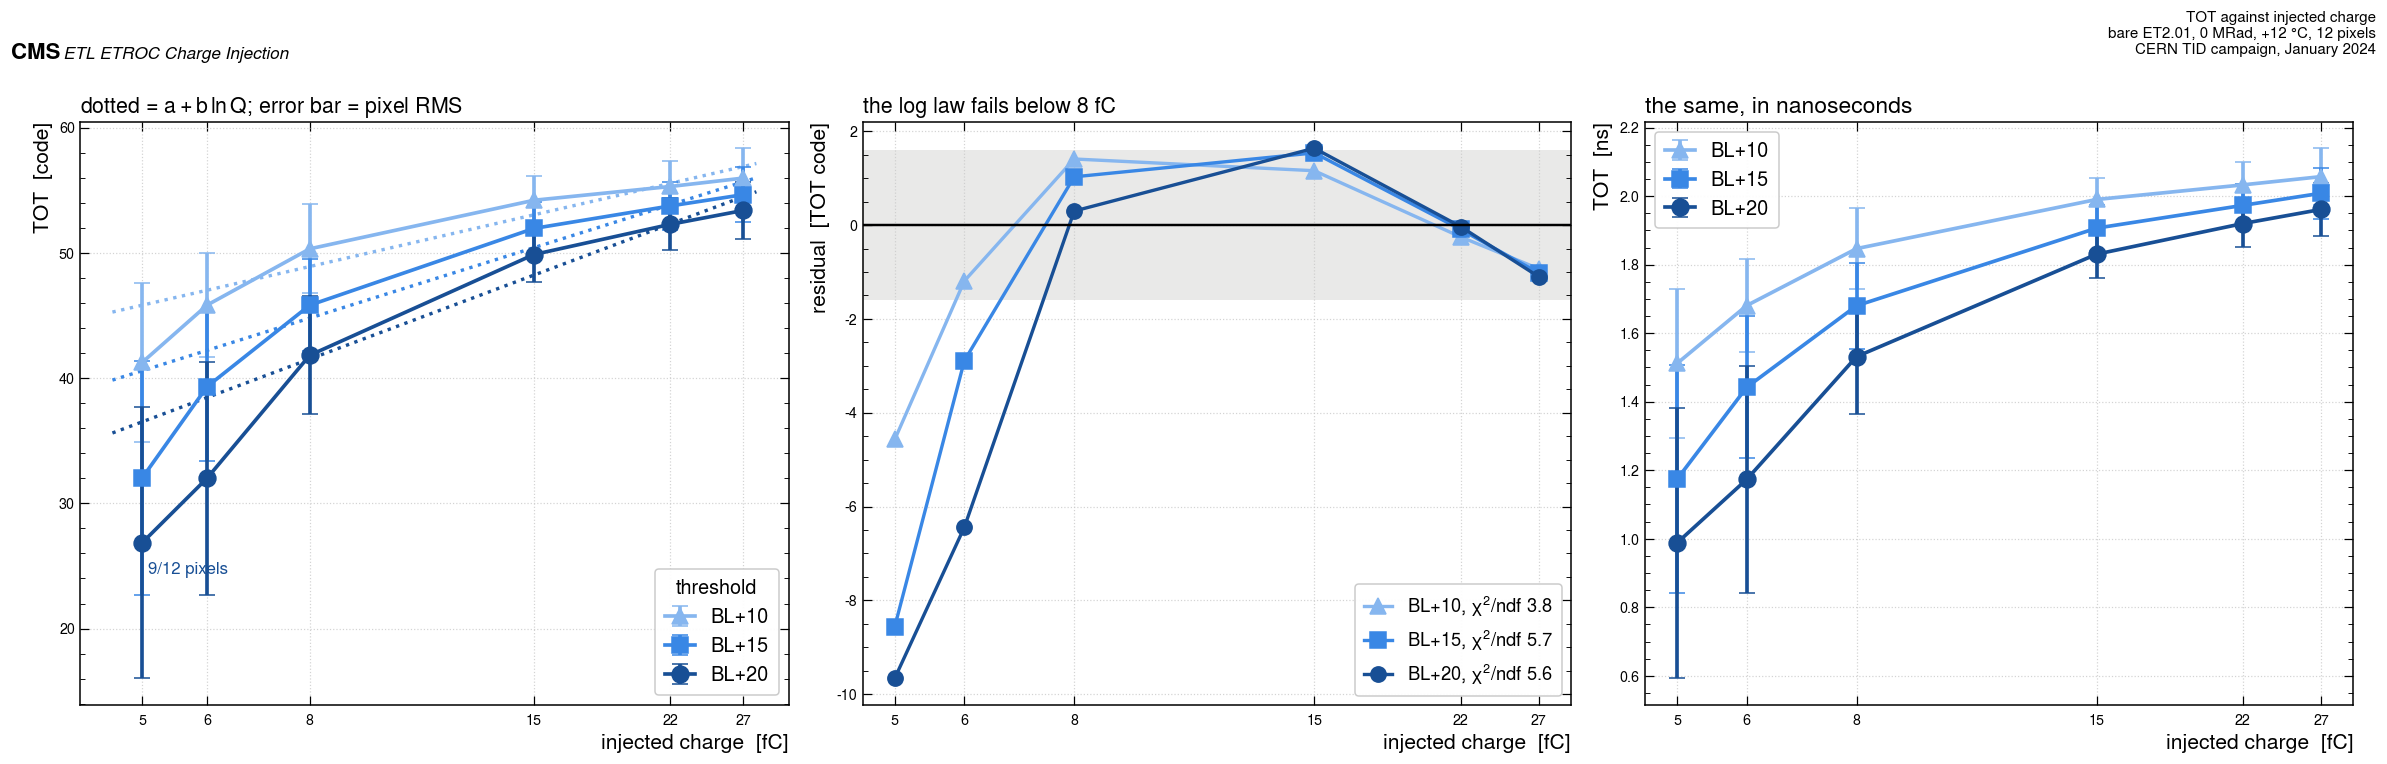

In [22]:
fig, axs = plt.subplots(1, 3, figsize=(21.5, 6.4))
ax = axs[0]
for off in Q.OFFS:
    s = TOT[TOT.offset == off].sort_values("charge_fC")
    ax.errorbar(s.charge_fC, s.tot_code_mean, yerr=s.tot_code_pixel_rms, fmt="-",
                marker=Q.OMK[off], ms=11, lw=2.4, color=Q.OCOL[off], capsize=5, label=f"BL+{off}")
    qq = np.linspace(4.6, 28, 200)
    ax.plot(qq, fits[off]["a"] + fits[off]["b"] * np.log(qq), ":", color=Q.OCOL[off], lw=2.2)
for ch in Q.CHARGES:
    n = TOT[(TOT.offset == 20) & (TOT.charge_fC == ch)].n_pixels.iloc[0]
    if n < 12:
        ax.annotate(f"{int(n)}/12 pixels", (ch, TOT[(TOT.offset == 20) & (TOT.charge_fC == ch)].tot_code_mean.iloc[0]),
                    textcoords="offset points", xytext=(4, -20), fontsize=11, color=Q.OCOL[20])
Q.charge_axis(ax)
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("TOT  [code]")
ax.legend(title="threshold", fontsize=13, title_fontsize=13)
ax.set_title("dotted = $a + b\\,\\ln Q$; error bar = pixel RMS", loc="left", fontsize=14)

ax = axs[1]
for off in Q.OFFS:
    s = TOT[TOT.offset == off].sort_values("charge_fC")
    ax.plot(s.charge_fC, list(fits[off]["res"].values()), "-", marker=Q.OMK[off], ms=10, lw=2.2,
            color=Q.OCOL[off], label=f"BL+{off}, $\\chi^2$/ndf {fits[off]['chi2_ndf']:.1f}")
ax.axhline(0, color="black", lw=1.6)
ax.axhspan(-1.6, 1.6, color=Q.GREY, alpha=0.18, lw=0)
Q.charge_axis(ax)
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("residual  [TOT code]")
ax.legend(fontsize=12)
ax.set_title("the log law fails below 8 fC", loc="left", fontsize=14)

ax = axs[2]
for off in Q.OFFS:
    s = TOT[TOT.offset == off].sort_values("charge_fC")
    ax.errorbar(s.charge_fC, s.tot_ns_mean, yerr=s.tot_ns_pixel_rms, fmt="-", marker=Q.OMK[off],
                ms=11, lw=2.4, color=Q.OCOL[off], capsize=5, label=f"BL+{off}")
Q.charge_axis(ax)
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("TOT  [ns]")
ax.legend(fontsize=13)
ax.set_title("the same, in nanoseconds", loc="left", fontsize=15)
fig.tight_layout()
Q.fig_header(fig, "TOT against injected charge", tag="bare ET2.01, 0 MRad, +12 °C, 12 pixels", scale=0.62, campaign=Q.BARE_CAMPAIGN)
Q.save_fig(fig, "bare_fig5_tot_vs_charge")
plt.show()

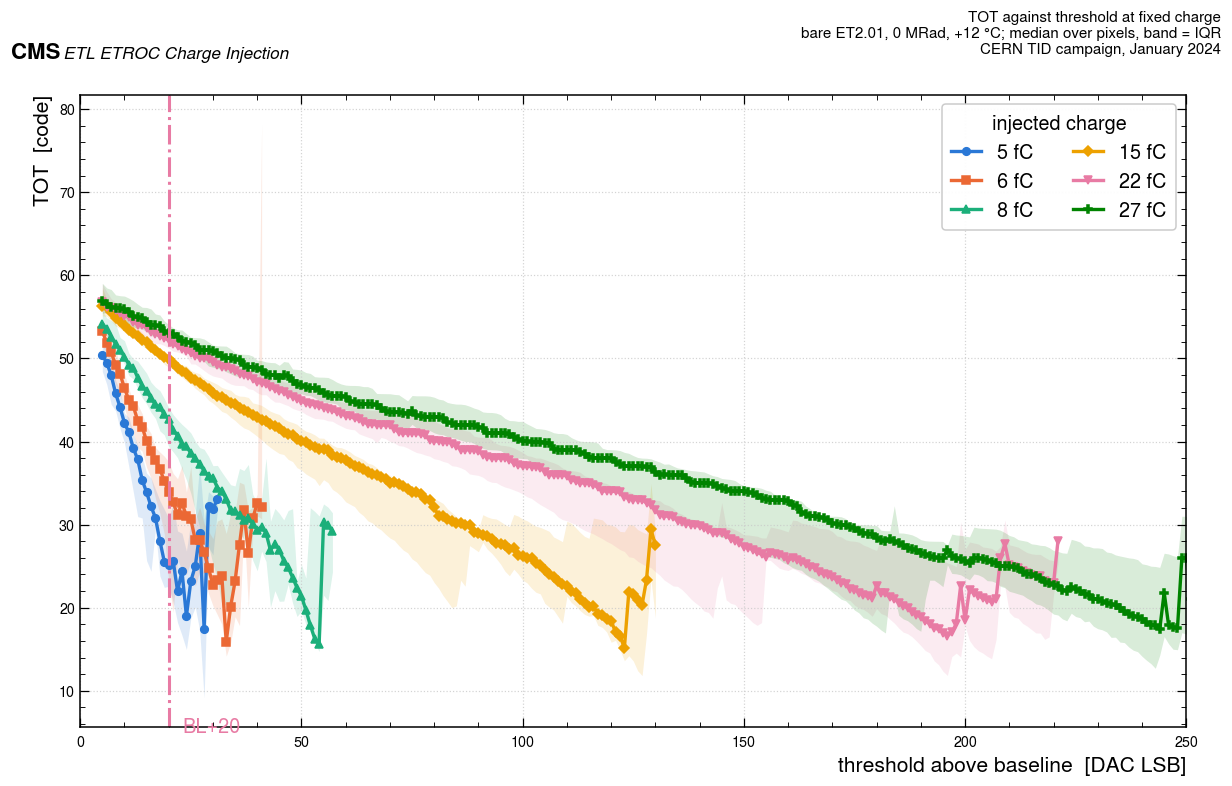

At fixed charge TOT falls with threshold, as it must: a higher threshold is crossed later
on the rising edge and earlier on the falling edge, so the pulse spends less time above it.


In [23]:
fig, ax = plt.subplots(figsize=(11, 6.6))
for ch in Q.CHARGES:
    sub = D0[D0.charge == ch]
    grp = sub.groupby("offset").tot_mean
    med, q1, q3, n = grp.median(), grp.quantile(0.25), grp.quantile(0.75), grp.size()
    keep = n >= 3
    ax.plot(med.index[keep], med[keep], "-", marker=Q.CMK[ch], ms=5, lw=2.2, color=Q.CCOL[ch],
            label=f"{ch} fC")
    ax.fill_between(med.index[keep], q1[keep], q3[keep], color=Q.CCOL[ch], alpha=0.15, lw=0)
ax.axvline(Q.OP_OFFSET, color=Q.C_MAG, ls="-.", lw=2)
ax.text(Q.OP_OFFSET + 3, 5, "BL+20", color=Q.C_MAG, fontsize=13)
ax.set_xlim(0, 250)
ax.set_xlabel("threshold above baseline  [DAC LSB]")
ax.set_ylabel("TOT  [code]")
ax.legend(title="injected charge", ncol=2, fontsize=13, title_fontsize=13)
fig.tight_layout()
Q.fig_header(fig, "TOT against threshold at fixed charge",
       tag="bare ET2.01, 0 MRad, +12 °C; median over pixels, band = IQR", scale=0.62, campaign=Q.BARE_CAMPAIGN)
Q.save_fig(fig, "bare_fig6_tot_vs_threshold")
plt.show()
print("At fixed charge TOT falls with threshold, as it must: a higher threshold is crossed later")
print("on the rising edge and earlier on the falling edge, so the pulse spends less time above it.")

## 10. Time walk and CAL stability

There are two distinct walks and they are not the same size.

* **Walk with threshold at fixed charge** — how much the measured TOA moves if the threshold
  is set a few DAC away from where it was meant to be.
* **Walk with charge at fixed threshold** — the dominant one, and the reason an offline
  time-walk correction exists at all. It is measured here against a *known* injected charge,
  which is precisely the handle beam data does not have.

Both are quoted from the pooled curve: the median TOA over pixels at each threshold, per
charge, so a single badly-behaved pixel cannot set the number.

In [24]:
walk_rows = []
for ch, g in D0.groupby("charge"):
    m = g.groupby("offset").toa_ns.median() * 1e3
    walk_rows.append(dict(charge_fC=ch, toa_at_BL5_ps=m.get(5, np.nan), toa_at_BL20_ps=m.get(20, np.nan),
                          walk_5to20_ps=m.get(20, np.nan) - m.get(5, np.nan),
                          walk_full_ps=m.iloc[-1] - m.iloc[0],
                          off_first=int(m.index[0]), off_last=int(m.index[-1])))
WALK = pd.DataFrame(walk_rows)
WALK.to_csv(Q.OUTDIR / "bare_walk.csv", index=False)
print(WALK.round(1).to_string(index=False))

t20 = D0[D0.offset == 20].groupby("charge").toa_ns.median() * 1e3
print("\nmedian TOA at BL+20 against charge [ps]:", t20.round(0).to_dict())
print("walk with charge, 5 -> 27 fC at BL+20:  %+.0f ps" % (t20[27] - t20[5]))
Q.check("walk with charge, 5->27 fC at BL+20", t20[27] - t20[5], 493, 3, "ps", LEDGER)
Q.check("median TOA at BL+20, 5 fC", t20[5], 4093, 3, "ps", LEDGER)
Q.check("median TOA at BL+20, 27 fC", t20[27], 4587, 3, "ps", LEDGER)
print("\nwalk with threshold over BL+5 -> BL+20, per charge [ps]:",
      dict(zip(WALK.charge_fC, WALK.walk_5to20_ps.round(0))))
print("walk with threshold over the full sweep, per charge [ps]:",
      dict(zip(WALK.charge_fC, WALK.walk_full_ps.round(0))))
RESULTS["walk_charge_5to27_at_off20_ps"] = float(t20[27] - t20[5])

 charge_fC  toa_at_BL5_ps  toa_at_BL20_ps  walk_5to20_ps  walk_full_ps  off_first  off_last
         5         4174.7          4093.3          -81.4        -218.2          5        47
         6         4252.9          4106.8         -146.1        -389.9          5        56
         8         4350.5          4285.4          -65.1        -214.9          5        84
        15         4509.1          4481.5          -27.6        -371.4          5       182
        22         4554.0          4571.2           17.2        -436.0          5       286
        27         4639.1          4586.6          -52.5        -542.2          5       350

median TOA at BL+20 against charge [ps]: {5: 4093.0, 6: 4107.0, 8: 4285.0, 15: 4481.0, 22: 4571.0, 27: 4587.0}
walk with charge, 5 -> 27 fC at BL+20:  +493 ps
[OK  ] walk with charge, 5->27 fC at BL+20                  recomputed   493.3397  published   493.0000  |d|   0.3397 (tol 3) ps
[OK  ] median TOA at BL+20, 5 fC                            recompu

CAL over the whole 0 MRad block: min 162.1, max 175.0, median 167.9 codes
median per-point CAL RMS: 0.434 codes (0.26 %)
points outside the pipeline guard band (100, 220): 0 of 7453
[OK  ] median per-point CAL RMS                             recomputed     0.4341  published     0.4300  |d|   0.0041 (tol 0.01) code


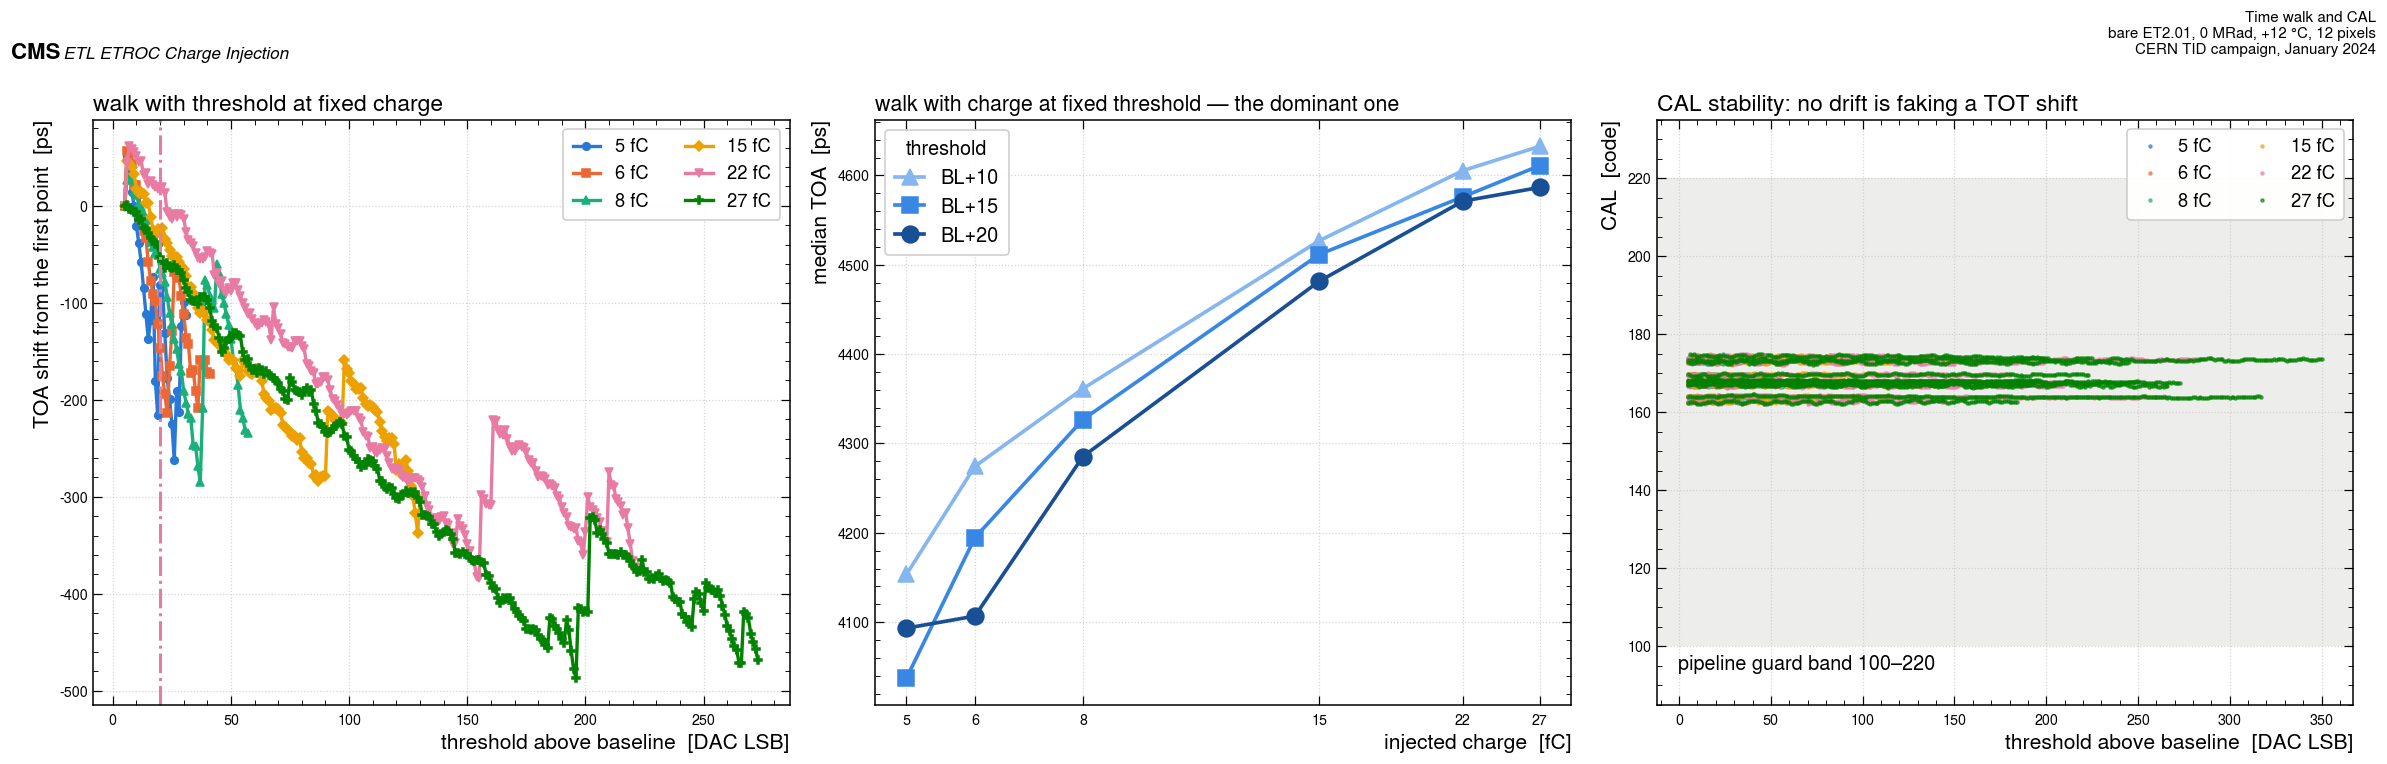

In [25]:
cal_med_rms = D0.cal_std.median()
print("CAL over the whole 0 MRad block: min %.1f, max %.1f, median %.1f codes"
      % (D0.cal_mean.min(), D0.cal_mean.max(), D0.cal_mean.median()))
print("median per-point CAL RMS: %.3f codes (%.2f %%)" % (cal_med_rms, 100 * cal_med_rms / D0.cal_mean.median()))
print("points outside the pipeline guard band %s: %d of %d"
      % (Q.CAL_GUARD, int(((D0.cal_mean < Q.CAL_GUARD[0]) | (D0.cal_mean > Q.CAL_GUARD[1])).sum()), len(D0)))
Q.check("median per-point CAL RMS", cal_med_rms, 0.43, 0.01, "code", LEDGER)

fig, axs = plt.subplots(1, 3, figsize=(21.5, 6.4))
ax = axs[0]
for ch in Q.CHARGES:
    sub = D0[D0.charge == ch]
    m = sub.groupby("offset").toa_ns.median() * 1e3
    n = sub.groupby("offset").size()
    keep = n >= 3
    ax.plot(m.index[keep], m[keep] - m[keep].iloc[0], "-", marker=Q.CMK[ch], ms=5, lw=2.2,
            color=Q.CCOL[ch], label=f"{ch} fC")
ax.axvline(Q.OP_OFFSET, color=Q.C_MAG, ls="-.", lw=2)
ax.set_xlabel("threshold above baseline  [DAC LSB]")
ax.set_ylabel("TOA shift from the first point  [ps]")
ax.legend(fontsize=12, ncol=2)
ax.set_title("walk with threshold at fixed charge", loc="left", fontsize=15)

ax = axs[1]
for off in Q.OFFS:
    s = D0[D0.offset == off].groupby("charge").toa_ns.median() * 1e3
    ax.plot(s.index, s.values, "-", marker=Q.OMK[off], ms=11, lw=2.4, color=Q.OCOL[off],
            label=f"BL+{off}")
Q.charge_axis(ax)
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("median TOA  [ps]")
ax.legend(title="threshold", fontsize=13, title_fontsize=13)
ax.set_title("walk with charge at fixed threshold — the dominant one", loc="left", fontsize=14)

ax = axs[2]
for ch in Q.CHARGES:
    sub = D0[D0.charge == ch]
    ax.plot(sub.offset, sub.cal_mean, ".", ms=4, color=Q.CCOL[ch], alpha=0.6, label=f"{ch} fC")
ax.axhspan(*Q.CAL_GUARD, color=Q.GREY, alpha=0.15, lw=0)
ax.set_ylim(min(Q.CAL_GUARD) - 15, max(Q.CAL_GUARD) + 15)
ax.set_xlabel("threshold above baseline  [DAC LSB]")
ax.set_ylabel("CAL  [code]")
ax.text(0.03, 0.06, "pipeline guard band 100–220", transform=ax.transAxes, fontsize=13)
ax.legend(fontsize=12, ncol=2, loc="upper right")
ax.set_title("CAL stability: no drift is faking a TOT shift", loc="left", fontsize=15)
fig.tight_layout()
Q.fig_header(fig, "Time walk and CAL", tag="bare ET2.01, 0 MRad, +12 °C, 12 pixels", scale=0.62, campaign=Q.BARE_CAMPAIGN)
Q.save_fig(fig, "bare_fig7_walk_and_cal")
plt.show()

## 11. Dose and temperature — resolving the confound

The 0 MRad sweep is at +12 °C and both irradiated sweeps are at −25 °C, so the summary alone
cannot say whether a change is dose or temperature. The `2024-01-12` turn-off files supply the
missing corner, 0 MRad at −25 °C, and with the same 8–27 fC fit throughout the two effects
separate.

In [26]:
tid = GB.copy()
tid["gain_rel_to_0MRad_12C"] = tid.gain_dac_per_fc / ref.gain_dac_per_fc
tid["condition"] = [Q.cond_label(d, t) for d, t in zip(tid.dose, tid.temp)]
show = tid[["condition", "n_pixels", "gain_dac_per_fc", "gain_sem", "gain_mv_per_fc",
            "BL_mean", "gain_rel_to_0MRad_12C"]].round(3)
print(show.to_string(index=False))

g_0_12 = float(tid[(tid.dose == 0) & (tid.temp == 12)].gain_dac_per_fc.iloc[0])
g_0_m25 = float(tid[(tid.dose == 0) & (tid.temp == -25)].gain_dac_per_fc.iloc[0])
g_400 = float(tid[(tid.dose == 400)].gain_dac_per_fc.iloc[0])
b = tid.set_index(["dose", "temp"]).BL_mean
print("\ncooling +12 -> -25 °C at 0 MRad      : gain x %.4f  (%+.1f %%)"
      % (g_0_m25 / g_0_12, 100 * (g_0_m25 / g_0_12 - 1)))
print("0 -> 400 MRad at a fixed -25 °C      : gain x %.4f  (%+.1f %%)"
      % (g_400 / g_0_m25, 100 * (g_400 / g_0_m25 - 1)))
print("\nbaseline shifts [DAC]:")
print("  cooling +12 -> -25 °C : %+.1f" % (b[(0, -25)] - b[(0, 12)]))
print("  0 -> 200 MRad         : %+.1f" % (b[(200, -25)] - b[(0, -25)]))
print("  200 -> 400 MRad       : %+.1f" % (b[(400, -25)] - b[(200, -25)]))
print("  baseline vs temperature at 0 MRad: %.2f DAC/°C" % ((b[(0, 12)] - b[(0, -25)]) / (12 - -25)))
Q.check("gain change on cooling +12 -> -25 °C", 100 * (g_0_m25 / g_0_12 - 1), -7.7, 0.15, "%", LEDGER)
Q.check("gain change 0 -> 400 MRad at -25 °C", 100 * (g_400 / g_0_m25 - 1), -5.4, 0.15, "%", LEDGER)
Q.check("baseline shift on cooling", b[(0, -25)] - b[(0, 12)], 77, 1.0, "DAC", LEDGER)
Q.check("baseline shift 0 -> 200 MRad", b[(200, -25)] - b[(0, -25)], 25, 1.0, "DAC", LEDGER)
Q.check("baseline shift 200 -> 400 MRad", b[(400, -25)] - b[(200, -25)], 21, 1.0, "DAC", LEDGER)
RESULTS["bl_per_degC_at_0MRad"] = float((b[(0, 12)] - b[(0, -25)]) / (12 - -25))

       condition  n_pixels  gain_dac_per_fc  gain_sem  gain_mv_per_fc  BL_mean  gain_rel_to_0MRad_12C
  0 MRad, -25 °C        12            8.691     0.861           3.395  523.417                  0.923
  0 MRad, +12 °C        12            9.416     0.892           3.678  446.500                  1.000
200 MRad, -25 °C        12            8.315     0.826           3.248  548.250                  0.883
400 MRad, -25 °C        12            8.216     0.826           3.209  569.667                  0.873

cooling +12 -> -25 °C at 0 MRad      : gain x 0.9230  (-7.7 %)
0 -> 400 MRad at a fixed -25 °C      : gain x 0.9453  (-5.5 %)

baseline shifts [DAC]:
  cooling +12 -> -25 °C : +76.9
  0 -> 200 MRad         : +24.8
  200 -> 400 MRad       : +21.4
  baseline vs temperature at 0 MRad: -2.08 DAC/°C
[OK  ] gain change on cooling +12 -> -25 °C                 recomputed    -7.6997  published    -7.7000  |d|   0.0003 (tol 0.15) %
[OK  ] gain change 0 -> 400 MRad at -25 °C                  re

### 12.1 The same dose steps as a **paired per-pixel** ratio

The numbers above are ratios of the *pooled* gain — one condition's mean over pixels divided by
another's — which carries no error at all, because the pixel-to-pixel spread (33 % here) swamps
the change being measured. The same twelve pixels were fitted at every condition, so the ratio
can instead be formed **pixel by pixel and then averaged**, which cancels the pixel spread
exactly as notebook 03 does on its six ET2.03 pixels. This is the estimator notebook 04 needs if
the two campaigns' dose numbers are to be compared like with like; both are printed here, and
the difference between them is the pairing, not the data.

In [27]:
gpix = GF.set_index(["dose", "temp", "row", "col"]).gain_dac_per_fc
blpix = BL.set_index(["dose", "temp", "row", "col"]).BL
pair_rows = []
for d0, d1 in [(0, 200), (200, 400), (0, 400)]:
    a = gpix.loc[(d0, -25)].dropna()
    b_ = gpix.loc[(d1, -25)].dropna()
    common = a.index.intersection(b_.index)
    r = (b_[common] / a[common]).astype(float)
    ba, bb = blpix.loc[(d0, -25)], blpix.loc[(d1, -25)]
    bix = ba.index.intersection(bb.index)
    dbl = (bb[bix] - ba[bix]).astype(float)
    pair_rows.append(dict(temp=-25, dose_from=d0, dose_to=d1, n_pixels=len(r),
                          gain_ratio=r.mean(), gain_ratio_sem=r.std(ddof=1) / np.sqrt(len(r)),
                          gain_ratio_pixel_rms=r.std(ddof=1),
                          gain_change_pct=100 * (r.mean() - 1),
                          gain_change_pct_pooled=100 * (float(b_[common].mean()) / float(a[common].mean()) - 1),
                          BL_shift_dac=float(bb[common].mean() - ba[common].mean()),
                          BL_shift_paired_dac=float(dbl.mean()),
                          BL_shift_sem=float(dbl.std(ddof=1) / np.sqrt(len(dbl))),
                          BL_shift_pixel_rms=float(dbl.std(ddof=1)),
                          BL_shift_n_pixels=int(len(dbl))))
PAIR01 = pd.DataFrame(pair_rows)
PAIR01.to_csv(Q.OUTDIR / "bare_paired_dose_ratios.csv", index=False)
print("paired per-pixel gain ratio with dose, at a fixed -25 °C, same 12 pixels throughout\n")
print(PAIR01.round(4).to_string(index=False))
p400 = PAIR01[(PAIR01.dose_from == 0) & (PAIR01.dose_to == 400)].iloc[0]
print("\n0 -> 400 MRad at -25 °C, %d pixels:" % p400.n_pixels)
print("  paired per pixel      : %+.1f +- %.1f %%  (pixel RMS %.1f)"
      % (p400.gain_change_pct, 100 * p400.gain_ratio_sem, 100 * p400.gain_ratio_pixel_rms))
print("  ratio of pooled means : %+.1f %%  (no error -- the estimator quoted above)"
      % p400.gain_change_pct_pooled)
RESULTS["gain_change_0to400_paired_pct"] = float(p400.gain_change_pct)
RESULTS["gain_change_0to400_paired_sem_pct"] = float(100 * p400.gain_ratio_sem)
RESULTS["gain_change_0to400_pooled_pct"] = float(p400.gain_change_pct_pooled)

paired per-pixel gain ratio with dose, at a fixed -25 °C, same 12 pixels throughout

 temp  dose_from  dose_to  n_pixels  gain_ratio  gain_ratio_sem  gain_ratio_pixel_rms  gain_change_pct  gain_change_pct_pooled  BL_shift_dac  BL_shift_paired_dac  BL_shift_sem  BL_shift_pixel_rms  BL_shift_n_pixels
  -25          0      200        12      0.9584          0.0221                0.0767          -4.1591                 -4.3309       24.8333              24.8333        4.3464             15.0565                 12
  -25        200      400        12      0.9758          0.0230                0.0795          -2.4232                 -1.1883       21.4167              21.4167        4.0554             14.0483                 12
  -25          0      400        12      0.9354          0.0318                0.1102          -6.4638                 -5.4677       46.2500              46.2500        8.3812             29.0333                 12

0 -> 400 MRad at -25 °C, 12 pixels:
  paired per pixel

/var/folders/st/45tl5ffn70sg25zsxp7lfsb40000gq/T/ipykernel_71096/3721422403.py:9: PerformanceWarning: indexing past lexsort depth may impact performance.
  ba, bb = blpix.loc[(d0, -25)], blpix.loc[(d1, -25)]
/var/folders/st/45tl5ffn70sg25zsxp7lfsb40000gq/T/ipykernel_71096/3721422403.py:9: PerformanceWarning: indexing past lexsort depth may impact performance.
  ba, bb = blpix.loc[(d0, -25)], blpix.loc[(d1, -25)]
/var/folders/st/45tl5ffn70sg25zsxp7lfsb40000gq/T/ipykernel_71096/3721422403.py:9: PerformanceWarning: indexing past lexsort depth may impact performance.
  ba, bb = blpix.loc[(d0, -25)], blpix.loc[(d1, -25)]


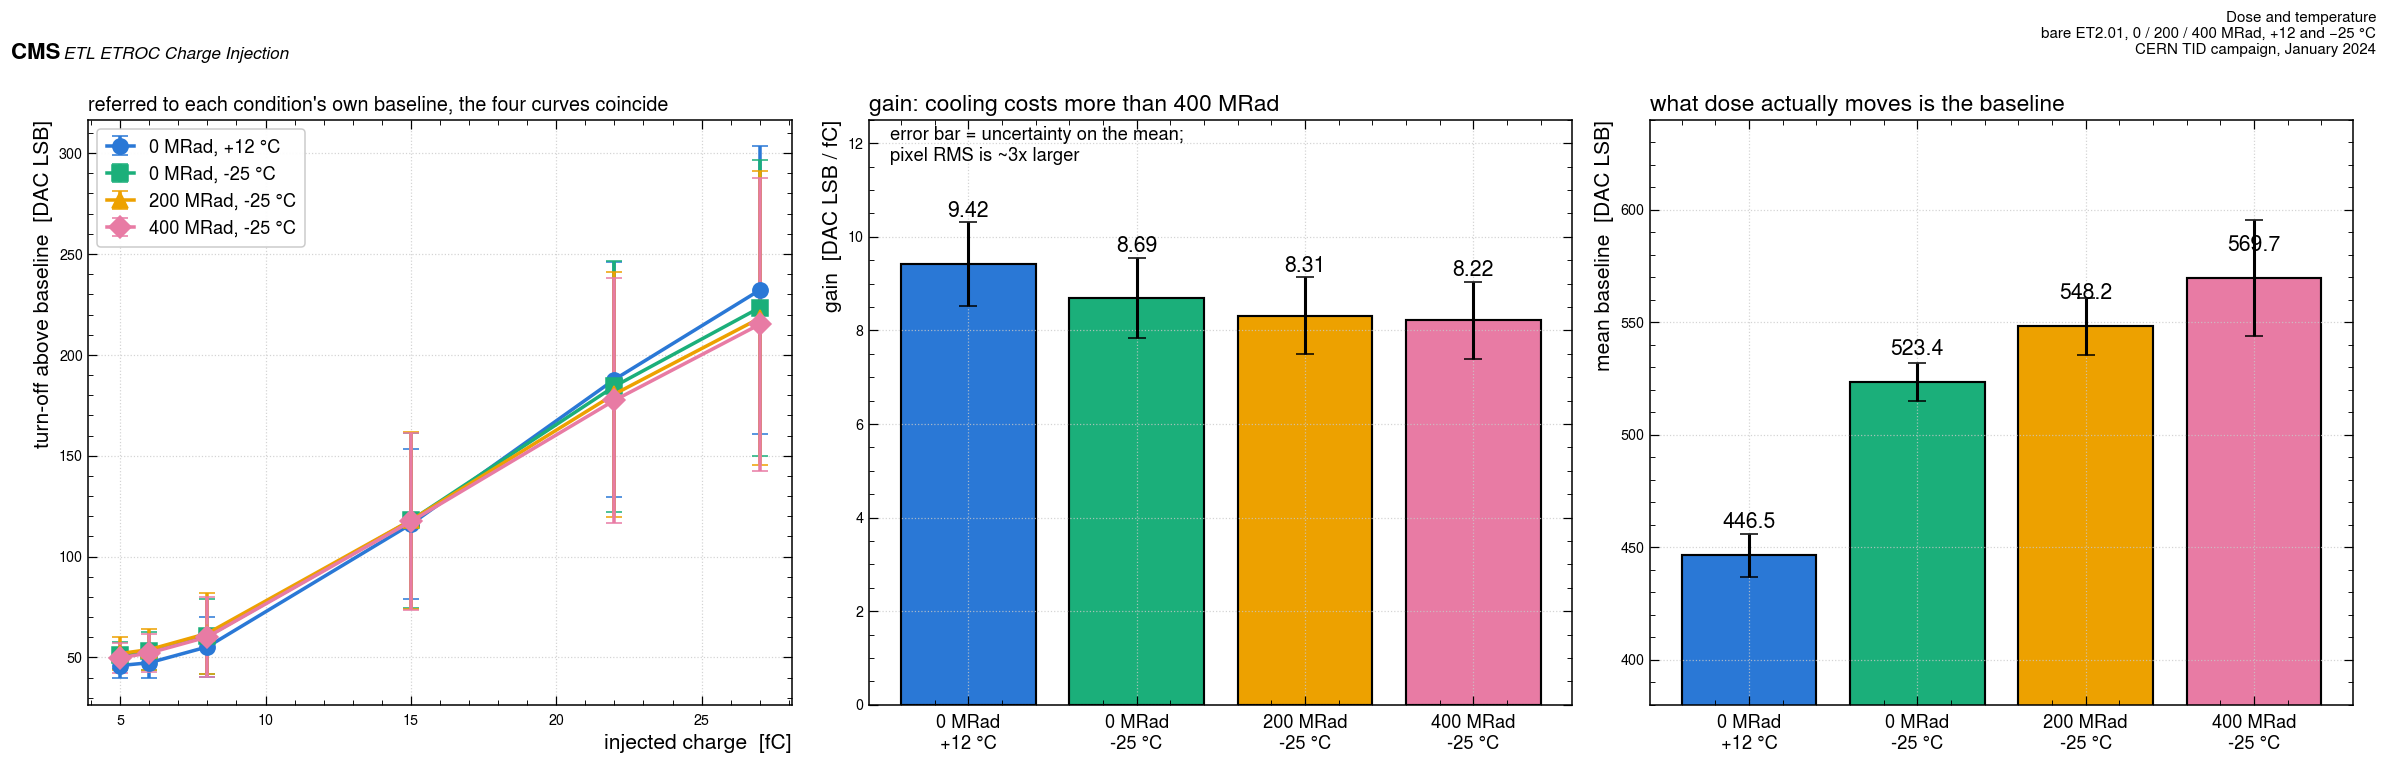

In [28]:
COND_COL = {(0, 12): Q.C_BLUE, (0, -25): Q.C_AQUA, (200, -25): Q.C_YELLOW, (400, -25): Q.C_MAG}
COND_MK = {(0, 12): "o", (0, -25): "s", (200, -25): "^", (400, -25): "D"}
fig, axs = plt.subplots(1, 3, figsize=(21.5, 6.4))
ax = axs[0]
for k in Q.BARE_CONDITIONS:
    g = TO[(TO.dose == k[0]) & (TO.temp == k[1])]
    p = g.groupby("charge").trig_turnoff_offset.agg(["mean", "std"])
    ax.errorbar(p.index, p["mean"], yerr=p["std"], fmt="-", marker=COND_MK[k], ms=10, lw=2.3,
                color=COND_COL[k], capsize=5, label=Q.cond_label(*k))
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("turn-off above baseline  [DAC LSB]")
ax.legend(fontsize=12)
ax.set_title("referred to each condition's own baseline, the four curves coincide",
             loc="left", fontsize=13)

ax = axs[1]
xs = np.arange(len(Q.BARE_CONDITIONS))
vals = [float(tid[(tid.dose == k[0]) & (tid.temp == k[1])].gain_dac_per_fc.iloc[0]) for k in Q.BARE_CONDITIONS]
errs = [float(tid[(tid.dose == k[0]) & (tid.temp == k[1])].gain_sem.iloc[0]) for k in Q.BARE_CONDITIONS]
ax.bar(xs, vals, yerr=errs, capsize=6, color=[COND_COL[k] for k in Q.BARE_CONDITIONS],
       edgecolor="black", lw=1.4)
for x, v, e in zip(xs, vals, errs):
    ax.text(x, v + e + 0.12, f"{v:.2f}", ha="center", fontsize=14)
ax.set_xticks(xs)
ax.set_xticklabels([Q.cond_label(*k).replace(", ", "\n") for k in Q.BARE_CONDITIONS], fontsize=12)
ax.set_ylabel("gain  [DAC LSB / fC]")
ax.set_ylim(0, 12.5)
ax.text(0.03, 0.93, "error bar = uncertainty on the mean;\npixel RMS is ~3x larger",
        transform=ax.transAxes, fontsize=12)
ax.set_title("gain: cooling costs more than 400 MRad", loc="left", fontsize=15)

ax = axs[2]
ax.bar(xs, [float(b[k]) for k in Q.BARE_CONDITIONS],
       yerr=[float(tid[(tid.dose == k[0]) & (tid.temp == k[1])].n_pixels.iloc[0]) * 0 +
             float(BL[(BL.dose == k[0]) & (BL.temp == k[1])].BL.std()) for k in Q.BARE_CONDITIONS],
       capsize=6, color=[COND_COL[k] for k in Q.BARE_CONDITIONS], edgecolor="black", lw=1.4)
for x, k in zip(xs, Q.BARE_CONDITIONS):
    ax.text(x, float(b[k]) + 12, f"{float(b[k]):.1f}", ha="center", fontsize=14)
ax.set_xticks(xs)
ax.set_xticklabels([Q.cond_label(*k).replace(", ", "\n") for k in Q.BARE_CONDITIONS], fontsize=12)
ax.set_ylabel("mean baseline  [DAC LSB]")
ax.set_ylim(380, 640)
ax.set_title("what dose actually moves is the baseline", loc="left", fontsize=15)
fig.tight_layout()
Q.fig_header(fig, "Dose and temperature", tag="bare ET2.01, 0 / 200 / 400 MRad, +12 and −25 °C", scale=0.62, campaign=Q.BARE_CAMPAIGN)
Q.save_fig(fig, "bare_fig8_dose_and_temperature")
plt.show()

### The confound, stated plainly

Cooling from +12 to −25 °C costs about 8 % of gain; a further 400 MRad at fixed −25 °C costs
about 5 %. Both are well inside the 33 % pixel-to-pixel spread, so neither is a large effect
on this chip. What dose does move, unambiguously, is the **baseline**: +77 DAC for the
cooling, then +25 and +21 DAC for the first and second 200 MRad.

Referred to each condition's own baseline the four turn-off curves lie on top of one another.
The operational statement that follows is the useful one: **to 400 MRad, re-running
autocalibration and working at a fixed offset above the new baseline recovers essentially the
same response** — which is exactly what the beam pipeline does with `threshold = BL + 20`.

Two limits on that statement. The 0 MRad / −25 °C corner has turn-off files only, so it
contributes gain and baseline but nothing about TOT or jitter; the temperature effect is
bounded here only through the turn-off. And the 200 and 400 MRad blocks are the same die after
irradiation, with an annealing history that is not recorded anywhere in this data set.

### 11.2 The X-ray footprint on W36_6

The autocalibration maps of `2024-01-11` (0 MRad, +12 °C), `2024-01-12` (0 MRad, −25 °C) and
`2024-01-15` (200 MRad, −25 °C) are full 256-pixel maps, so they show **where the X-ray spot was**.
On a fixed external reference nothing chip-wide should move with dose, so rows outside the spot
are a null test and rows inside it carry the front-end drift alone.

In [29]:
bm = BN.pivot_table(index=["row", "col"], columns="day", values="baseline_dac")
cool = (bm["2024-01-12"] - bm["2024-01-11"]).groupby(level="row").agg(["mean", "std"])
d200 = (bm["2024-01-15"] - bm["2024-01-12"]).groupby(level="row").agg(["mean", "std"])
FOOT01 = pd.DataFrame({"row": d200.index, "cooldown_12_to_m25_dac": cool["mean"].values, "cooldown_col_rms": cool["std"].values,
                       "shift_0_200_dac": d200["mean"].values, "shift_0_200_col_rms": d200["std"].values})
FOOT01.to_csv(Q.OUTDIR / "bare_footprint_by_row.csv", index=False)
print("W36_6, 256-pixel maps, per-row baseline change [DAC]:\n")
print(FOOT01.round(1).to_string(index=False))
in_rows, out_rows = [0, 1, 2, 3], list(range(6, 16))
s_in = float(FOOT01[FOOT01.row.isin(in_rows)].shift_0_200_dac.mean())
s_out = float(FOOT01[FOOT01.row.isin(out_rows)].shift_0_200_dac.mean())
print("\n0 -> 200 MRad: rows 0-3 %+.1f DAC, rows 4-5 the edge, rows 6-15 %+.1f DAC; the cooldown is %+.1f DAC on every row alike."
      % (s_in, s_out, FOOT01.cooldown_12_to_m25_dac.mean()))
print("So the X-ray spot covered rows 0-3 of this die, the rest of the die saw no dose, and on a FIXED external")
print("reference the un-irradiated rows do not move (%+.1f DAC): the null test passes." % s_out)
print("The twelve money-plot pixels are rows {0, 1, 3, 12} x columns {2, 8, 14}: NINE inside the spot, THREE (row 12) outside.")
gpix_ = GF.set_index(["dose", "temp", "row", "col"]).gain_dac_per_fc
blpix_ = BL.set_index(["dose", "temp", "row", "col"]).BL
split_rows = []
for grp, rows_ in (("inside the spot (rows 0, 1, 3)", [0, 1, 3]), ("outside the spot (row 12)", [12])):
    for d1 in (200, 400):
        a, b_ = gpix_.loc[(0, -25)], gpix_.loc[(d1, -25)]
        ba, bb = blpix_.loc[(0, -25)], blpix_.loc[(d1, -25)]
        ix = [k for k in a.index.intersection(b_.index) if k[0] in rows_]
        r = (b_[ix] / a[ix]).astype(float); db = (bb[ix] - ba[ix]).astype(float)
        split_rows.append(dict(pixels=grp, n_pixels=len(r), dose_to=d1, bl_shift_dac=db.mean(),
                               bl_shift_sem=db.std(ddof=1) / np.sqrt(len(db)) if len(db) > 1 else np.nan,
                               gain_change_pct=100 * (r.mean() - 1),
                               gain_change_sem_pct=100 * r.std(ddof=1) / np.sqrt(len(r)) if len(r) > 1 else np.nan))
SPLIT01 = pd.DataFrame(split_rows)
SPLIT01.to_csv(Q.OUTDIR / "bare_footprint_split.csv", index=False)
print("\nthe twelve pixels split by where they sit (in-configuration baselines and per-pixel gain fits, -25 C):\n")
print(SPLIT01.round(2).to_string(index=False))
print("\nEvery 'twelve-pixel' dose number above is therefore a 9:3 mixture. The inside-spot rows give the front-end")
print("drift on this die; row 12 is a null.")
RESULTS["footprint"] = dict(rows_in_spot=in_rows, shift_in_0_200=s_in, shift_out_0_200=s_out,
                            split=SPLIT01.to_dict("records"))

W36_6, 256-pixel maps, per-row baseline change [DAC]:

 row  cooldown_12_to_m25_dac  cooldown_col_rms  shift_0_200_dac  shift_0_200_col_rms
   0                    76.9               2.2             35.0                  2.6
   1                    75.7               2.3             37.4                  2.5
   2                    76.9               1.9             33.7                  2.0
   3                    77.0               1.2             22.2                  2.0
   4                    76.2               1.4             12.2                  2.7
   5                    76.2               1.9              3.6                  2.0
   6                    76.1               1.7              1.6                  0.9
   7                    76.6               2.1              0.4                  1.2
   8                    76.8               1.0              1.0                  1.6
   9                    76.9               1.4             -0.2                  1.2
  10      

/var/folders/st/45tl5ffn70sg25zsxp7lfsb40000gq/T/ipykernel_71096/3219440451.py:23: PerformanceWarning: indexing past lexsort depth may impact performance.
  ba, bb = blpix_.loc[(0, -25)], blpix_.loc[(d1, -25)]
/var/folders/st/45tl5ffn70sg25zsxp7lfsb40000gq/T/ipykernel_71096/3219440451.py:23: PerformanceWarning: indexing past lexsort depth may impact performance.
  ba, bb = blpix_.loc[(0, -25)], blpix_.loc[(d1, -25)]
/var/folders/st/45tl5ffn70sg25zsxp7lfsb40000gq/T/ipykernel_71096/3219440451.py:23: PerformanceWarning: indexing past lexsort depth may impact performance.
  ba, bb = blpix_.loc[(0, -25)], blpix_.loc[(d1, -25)]
/var/folders/st/45tl5ffn70sg25zsxp7lfsb40000gq/T/ipykernel_71096/3219440451.py:23: PerformanceWarning: indexing past lexsort depth may impact performance.
  ba, bb = blpix_.loc[(0, -25)], blpix_.loc[(d1, -25)]


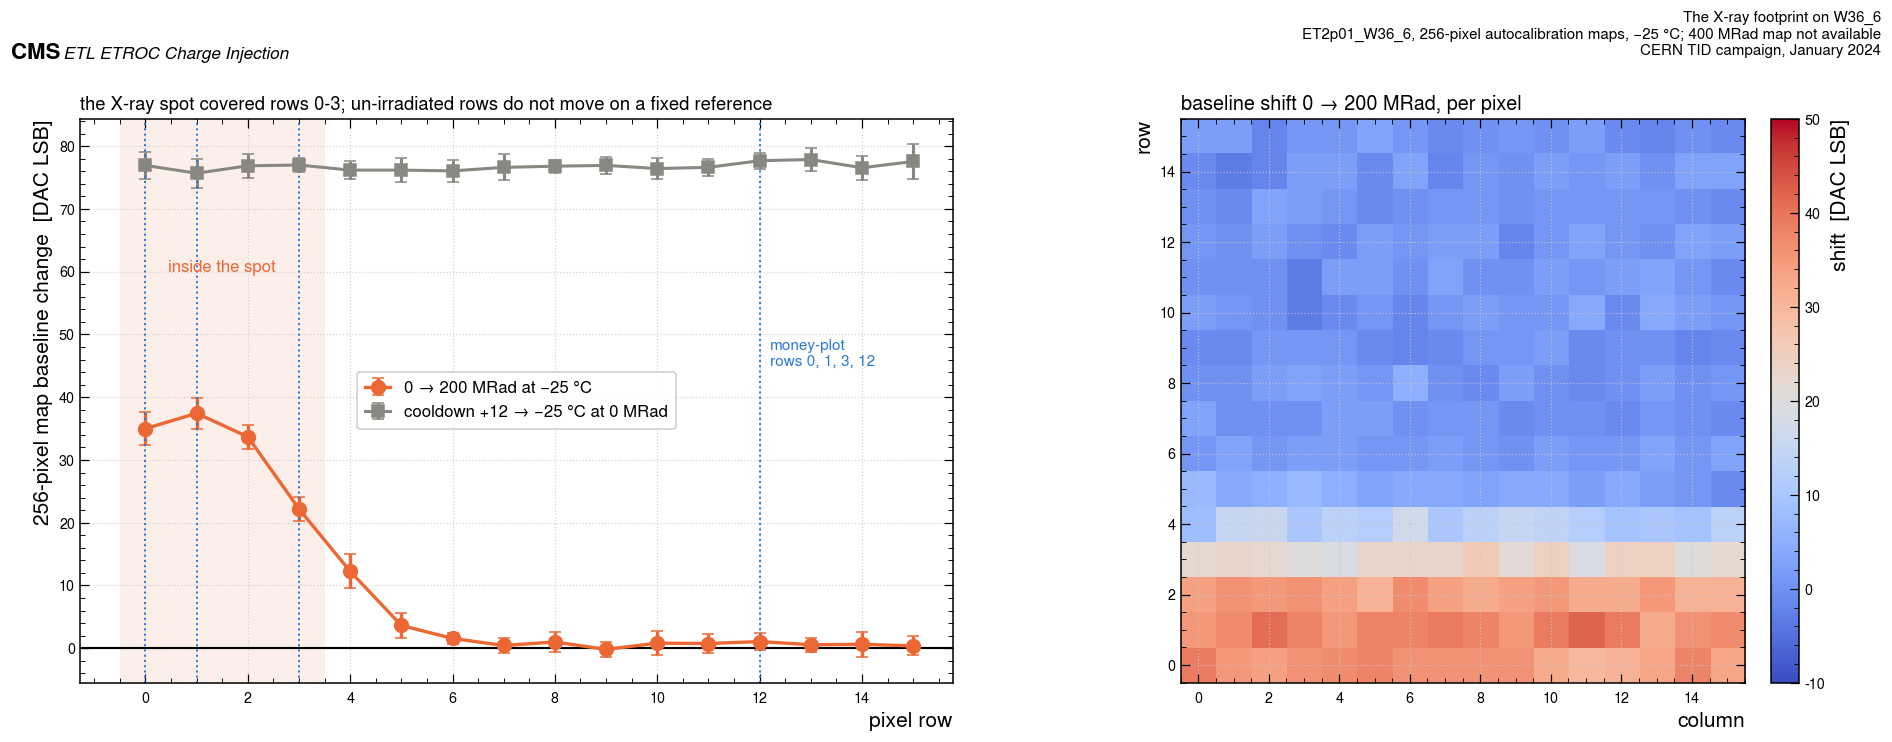

In [30]:
fig, axs = plt.subplots(1, 2, figsize=(17, 6.2))
ax = axs[0]
ax.errorbar(FOOT01.row, FOOT01.shift_0_200_dac, yerr=FOOT01.shift_0_200_col_rms, fmt="-o", ms=9, lw=2.2, color=Q.C_ORANGE, capsize=4, label="0 → 200 MRad at −25 °C")
ax.errorbar(FOOT01.row, FOOT01.cooldown_12_to_m25_dac, yerr=FOOT01.cooldown_col_rms, fmt="-s", ms=8, lw=2.0, color=Q.GREY, capsize=4, label="cooldown +12 → −25 °C at 0 MRad")
ax.axhline(0, color="black", lw=1.4)
ax.axvspan(-0.5, 3.5, color=Q.C_ORANGE, alpha=0.10, lw=0)
ax.text(1.5, 60, "inside the spot", ha="center", fontsize=11, color=Q.C_ORANGE)
for r_ in (0, 1, 3, 12):
    ax.axvline(r_, color=Q.C_BLUE, ls=":", lw=1.3)
ax.text(12.2, 45, "money-plot\nrows 0, 1, 3, 12", fontsize=10, color=Q.C_BLUE)
ax.set_xlabel("pixel row"); ax.set_ylabel("256-pixel map baseline change  [DAC LSB]")
ax.legend(fontsize=11)
ax.set_title("the X-ray spot covered rows 0-3; un-irradiated rows do not move on a fixed reference", loc="left", fontsize=12)
ax = axs[1]
im = ax.imshow((bm["2024-01-15"] - bm["2024-01-12"]).unstack("col").values, cmap="coolwarm", vmin=-10, vmax=50, origin="lower")
ax.set_xlabel("column"); ax.set_ylabel("row")
ax.set_title("baseline shift 0 → 200 MRad, per pixel", loc="left", fontsize=13)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03).set_label("shift  [DAC LSB]")
fig.tight_layout()
Q.fig_header(fig, "The X-ray footprint on W36_6",
             tag="ET2p01_W36_6, 256-pixel autocalibration maps, −25 °C; 400 MRad map not available", scale=0.62, campaign=Q.BARE_CAMPAIGN)
Q.save_fig(fig, "bare_fig9_footprint")
plt.show()

## 12. Summary

In [31]:
SUMMARY = pd.DataFrame([
    dict(n=1, quantity="Preamp gain (charge-to-threshold), 8–27 fC", value=f"{ref.gain_dac_per_fc:.2f} ± {ref.gain_sem:.2f}",
         unit="DAC/fC", pixel_rms=f"{ref.gain_pixel_rms:.2f}", label="DERIVED"),
    dict(n=2, quantity="the same in volts", value=f"{ref.gain_mv_per_fc:.2f} ± {ref.gain_mv_sem:.2f}",
         unit="mV/fC", pixel_rms=f"{ref.gain_mv_pixel_rms:.2f}", label="DERIVED"),
    dict(n=3, quantity="Turn-off above baseline at 15 fC",
         value=f"{tab.trig_turnoff_offset_mean[15]:.1f}", unit="DAC",
         pixel_rms=f"{tab.trig_pixel_rms[15]:.1f}", label="DERIVED from RAW FPGA counters"),
    dict(n=4, quantity="TOT at BL+20, 15 fC",
         value=f"{TOT[(TOT.offset == 20) & (TOT.charge_fC == 15)].tot_code_mean.iloc[0]:.1f}",
         unit="TOT code", pixel_rms=f"{TOT[(TOT.offset == 20) & (TOT.charge_fC == 15)].tot_code_pixel_rms.iloc[0]:.1f}",
         label="DERIVED"),
    dict(n=5, quantity="TOA jitter at BL+20, 15 fC", value=f"{j20.loc[15, 'mean']:.1f}", unit="ps",
         pixel_rms=f"{j20.loc[15, 'std']:.1f}", label="DERIVED — at the quantisation floor"),
    dict(n=6, quantity="TOA jitter at BL+20, 5 fC", value=f"{j20.loc[5, 'mean']:.1f}", unit="ps",
         pixel_rms=f"{j20.loc[5, 'std']:.1f}", label="DERIVED — above the floor, 9/12 pixels"),
    dict(n=7, quantity="S-curve width σ (72 curves, shared σ)",
         value=f"{sigma:.2f} ± {sigma_sd:.2f}", unit=f"DAC = {sigma * Q.LSB_MV:.3f} mV",
         pixel_rms="—", label="DERIVED"),
    dict(n=8, quantity="ENC = σ / gain", value=f"{enc:.0f}", unit="electrons", pixel_rms="—",
         label="DERIVED — bare die, no input load"),
    dict(n=9, quantity="Autocal noise width NW", value=f"{nw0['mean']:.2f} ± {nw0['sem']:.2f}",
         unit="DAC", pixel_rms=f"{nw0['rms']:.2f}", label="RAW (NW_map)"),
    dict(n=10, quantity="Minimum charge reaching BL+20",
         value=f"{ref.Qmin_at_off20_fC:.1f} ± {ref.Qmin_sem:.1f}", unit="fC",
         pixel_rms=f"{ref.Qmin_pixel_rms:.1f}", label="DERIVED, extrapolated"),
    dict(n=11, quantity="TOT-to-charge law at BL+20",
         value=f"TOT = {fits[20]['a']:.1f} + {fits[20]['b']:.1f} ln(Q/fC)",
         unit=f"χ²/ndf {fits[20]['chi2_ndf']:.1f}", pixel_rms="—", label="DERIVED, valid 8–27 fC"),
    dict(n=12, quantity="TDC quantisation floor, LSB/√12", value=f"{floor_ps:.2f}", unit="ps",
         pixel_rms="—", label=f"DERIVED, TOA LSB {lsb_ps:.1f} ps"),
    dict(n=13, quantity="Walk with charge, 5→27 fC at BL+20", value=f"{t20[27] - t20[5]:+.0f}",
         unit="ps", pixel_rms="—", label="DERIVED, median over pixels"),
    dict(n=14, quantity="Gain change on cooling +12 → −25 °C",
         value=f"{100 * (g_0_m25 / g_0_12 - 1):+.1f}", unit="%", pixel_rms="—", label="DERIVED"),
    dict(n=15, quantity="Gain change 0 → 400 MRad at −25 °C, ratio of pooled means",
         value=f"{100 * (g_400 / g_0_m25 - 1):+.1f}", unit="%", pixel_rms="—",
         label="DERIVED — carries no error; the pixel spread swamps the change"),
    dict(n=16, quantity="Gain change 0 → 400 MRad at −25 °C, paired per pixel",
         value=f"{p400.gain_change_pct:+.1f} ± {100 * p400.gain_ratio_sem:.1f}", unit="%",
         pixel_rms=f"{100 * p400.gain_ratio_pixel_rms:.1f}",
         label=f"DERIVED — same {int(p400.n_pixels)} pixels at both doses; what notebook 04 compares"),
])
SUMMARY.to_csv(Q.OUTDIR / "bare_summary_numbers.csv", index=False)
print(SUMMARY.to_string(index=False))

 n                                                  quantity                      value           unit pixel_rms                                                             label
 1                Preamp gain (charge-to-threshold), 8–27 fC                9.42 ± 0.89         DAC/fC      3.09                                                           DERIVED
 2                                         the same in volts                3.68 ± 0.35          mV/fC      1.21                                                           DERIVED
 3                          Turn-off above baseline at 15 fC                      116.0            DAC      37.2                                    DERIVED from RAW FPGA counters
 4                                       TOT at BL+20, 15 fC                       49.9       TOT code       2.2                                                           DERIVED
 5                                TOA jitter at BL+20, 15 fC                        6.4             ps   

In [32]:
# Everything the companion hybrid notebook needs, written once, here.
RESULTS.update(
    chip="ET2p01_W36_6", kind="bare die, no sensor", campaign="CERN TID, January 2024",
    condition="0 MRad, +12 °C", n_pixels=int(ref.n_pixels),
    pixels=sorted(f"({r},{c})" for r, c in set(zip(D0.row, D0.col))),
    gain_sem=float(ref.gain_sem), gain_pixel_rms=float(ref.gain_pixel_rms),
    gain_mv_per_fc=float(ref.gain_mv_per_fc), Qmin_at_off20_fC=float(ref.Qmin_at_off20_fC),
    Qmin_sem=float(ref.Qmin_sem), intercept_offset_dac=float(ref.intercept_offset_dac),
    BL_mean=float(ref.BL_mean), cal_median=float(D0.cal_mean.median()),
    cal_median_point_rms=float(cal_med_rms),
    jitter_off20_by_charge={int(c): float(j20.loc[c, "mean"]) for c in j20.index},
    jitter_off20_rms_by_charge={int(c): float(j20.loc[c, "std"]) for c in j20.index},
    jitter_off20_n_by_charge={int(c): int(j20.loc[c, "size"]) for c in j20.index},
    tot_off20_by_charge={int(r.charge_fC): float(r.tot_code_mean)
                         for _, r in TOT[TOT.offset == 20].iterrows()},
    tot_off20_rms_by_charge={int(r.charge_fC): float(r.tot_code_pixel_rms)
                             for _, r in TOT[TOT.offset == 20].iterrows()},
    turnoff_off_by_charge={int(c): float(tab.trig_turnoff_offset_mean[c]) for c in tab.index},
    turnoff_off_rms_by_charge={int(c): float(tab.trig_pixel_rms[c]) for c in tab.index},
)
with open(Q.OUTDIR / "bare_results.json", "w") as fh:
    json.dump(RESULTS, fh, indent=1)
TOT[TOT.offset == 20].to_csv(Q.OUTDIR / "bare_tot_off20.csv", index=False)
pd.DataFrame(j20).reset_index().to_csv(Q.OUTDIR / "bare_jitter_off20.csv", index=False)
print("written to outputs/ for the companion notebook:")
for p in sorted(Q.OUTDIR.glob("bare_*")):
    print("  %-42s %8d B" % (p.name, p.stat().st_size))

written to outputs/ for the companion notebook:
  bare_footprint_by_row.csv                       942 B
  bare_footprint_split.csv                        514 B
  bare_gain_by_condition.csv                     1438 B
  bare_gain_fits.csv                             9718 B
  bare_jitter_off20.csv                           277 B
  bare_paired_dose_ratios.csv                     744 B
  bare_reproduction_ledger.csv                   4014 B
  bare_results.json                              3795 B
  bare_scurve_sigma_by_condition.csv              383 B
  bare_summary_numbers.csv                       1382 B
  bare_tot_off20.csv                              709 B
  bare_tot_vs_charge_offsets.csv                 1940 B
  bare_turnoff_all_conditions.csv               34456 B
  bare_vs_hybrid.csv                             1854 B
  bare_walk.csv                                   583 B


## 13. Reproduction ledger

Every headline number above was compared, in the cell that computed it, against the value
previously published for this data set. The ledger is collected here so a reader can see at a
glance what reproduces and what does not.

In [33]:
LED = pd.DataFrame(LEDGER)
LED["|diff|"] = LED["diff"].abs()
print(LED[["quantity", "recomputed", "published", "|diff|", "tol", "unit", "agrees"]]
      .round(4).to_string(index=False))
LED.to_csv(Q.OUTDIR / "bare_reproduction_ledger.csv", index=False)
n_ok = int(LED.agrees.sum())
print("\n%d of %d checks agree within tolerance." % (n_ok, len(LED)))
if n_ok < len(LED):
    print("\nDisagreements:")
    print(LED[~LED.agrees][["quantity", "recomputed", "published", "|diff|", "unit"]]
          .round(4).to_string(index=False))

                                     quantity  recomputed  published  |diff|   tol      unit  agrees
      discriminator turn-off above BL at 5 fC     45.9400      45.90  0.0400  0.15       DAC    True
      discriminator turn-off above BL at 6 fC     47.3400      47.30  0.0400  0.15       DAC    True
      discriminator turn-off above BL at 8 fC     55.2100      55.20  0.0100  0.15       DAC    True
     discriminator turn-off above BL at 15 fC    116.0300     116.00  0.0300  0.15       DAC    True
     discriminator turn-off above BL at 22 fC    187.7700     187.80  0.0300  0.15       DAC    True
     discriminator turn-off above BL at 27 fC    232.0900     232.10  0.0100  0.15       DAC    True
                          gain, 0 MRad +12 °C      9.4159       9.42  0.0041  0.02    DAC/fC    True
                 gain uncertainty on the mean      0.8919       0.89  0.0019  0.02    DAC/fC    True
                               gain pixel RMS      3.0897       3.09  0.0003  0.02    DAC/f

### The one substantive disagreement: the S-curve width

Everything reproduces except σ. The shared-σ fit above returns **0.92 DAC** where the previously
published value for this data set is **0.88 DAC**, and the ENC that follows is 610 rather than
584 electrons — about 4.5 % apart. Two things are worth saying about it.

First, the difference is an **estimator difference, not an arithmetic error**. The recipe the
published value came from — align each curve on its own fitted 50 % point, then fit one width to
the stack — is implemented in the same cell above, and it also returns 0.92 on this data. So the
0.88 is not recovered by either recipe here.

Second, **the 0.92 is independently corroborated**: the hybrid climate-chamber analysis
re-fitted this same bare probe table with its own implementation of the shared-σ estimator and
also obtained 0.92 ± 0.05 (its `summary_numbers.json`, key `bare_sigma_same_estimator`). Two
independent implementations agreeing on 0.92 is the stronger evidence, so **0.92 DAC and
610 e⁻ are what this notebook carries forward**, with 0.88 and 584 e⁻ noted as the earlier
published values.

Since ENC is quoted from a ratio, note also which half moved: σ here is a property of the
noise edge, and the gain is a property of the charge response. When the ENC is compared with
the sensor-loaded hybrid in the companion notebook, it is worth asking every time which of the
two did the moving.

---

## 14. Caveats

These limit what any of the numbers above can be used for, and none of them is removed by
care in the analysis.

1. **RFSel is not recorded** — not in a directory name, not in the summary, not in the
   autocalibration pickles. RFSel sets the preamplifier feedback resistance and therefore
   directly affects both gain and TOT. Every number here is at an unknown RFSel. This is the
   single largest unquantified systematic in this notebook.
2. **Power mode is not recorded either.**
3. **Chip revision.** This is ET2.01. The 2.01 → 2.02 revision fixed the on-chip voltage
   reference, which was about 167 mV low on 2.01, so the absolute DAC-to-millivolt scale is
   not guaranteed to carry to later hardware. That is a second reason every figure here uses
   offset above baseline rather than absolute DAC.
4. **No charge below 5 fC.** The region near the operating point where noise matters most is
   sampled by two points, and 5 fC reaches BL+20 on only 9 of 12 pixels.
5. **The only full sweep is at +12 °C**, not at an operational −25 °C. The temperature effect
   on gain is bounded here at about 8 % — but only through the turn-off, not through TOT or
   through jitter.
6. **TID history.** The 200 and 400 MRad blocks are the same die after irradiation; the
   annealing history is not recorded in this data set.
7. **The hit count is not an efficiency.** The sweep acquires for a fixed *time*, not for a
   fixed number of Level-1 accepts, and DAQ start/stop overhead varies, so the plateau
   scatters by roughly ±50 %. The hit count is used here only for error bars and for locating
   the turn-off edge. Efficiency statements come from the FPGA counters, which have a
   denominator.
8. **A missing (pixel, charge, threshold) row means zero hits, not "not scanned".** The
   directory census distinguishes the two, which is how the censoring flag is computed rather
   than assumed.
9. **About 0.8 % of point directories hold data but have no row in the summary** (counted in
   section 2). They are spread evenly over charges and doses and are too few to move anything,
   but they are a hole in the summary, not in the data.
10. **No cut is applied anywhere in this notebook.** What varies is coverage, and every
    pooled quantity reports its own `n`.